# 🍜 Cambodian Food Search (Khmer + English) → Telegram bot

An **Information Retrieval** project: search restaurants and online food sellers in Phnom Penh,
in **Khmer and English**, and answer through a **Telegram bot**.

| Step | Technique | Why |
|---|---|---|
| 3 | BM25 + fuzzy matching | classic keyword search, robust to typos |
| 4 | Multilingual embeddings + ChromaDB | search by *meaning*, across languages |
| 5 | Hybrid ranking + geo + filters | combine both, add distance, price and opening hours |
| 6 | CLIP image search | find food by photo |
| 7 | RAG with an LLM (Gemini → Ollama → plain cards) | friendly answers grounded in the results |
| 8 | Telegram bot | the user interface |
| 9 | Export | `src/` modules, `bot.py`, `requirements.txt`, `Dockerfile` |

**How to run (VS Code on a Mac):** open this folder in VS Code, select the kernel **venv (food-search)**
(or `./venv/bin/python`), then *Run All*. Steps that need a key you have not set (Telegram, Gemini)
are skipped with a message; they never stop the notebook.

## 0. Setup

**What:** find the project folder, install packages, import libraries, pick the compute device, load settings and secrets.

**Why:** everything later depends on it. The paths are relative to the project root (the folder that contains
this notebook), so the project works on any computer. On Google Colab the same cells adapt automatically.

> ⚠️ **Secrets:** never paste API keys or tokens into this notebook, and never commit `.env`.
> Keys live only in `.env` (VS Code / local) or in *Colab → Secrets*. The notebook prints only *set* / *missing*.

In [1]:
# Where are we running? VS Code / local Jupyter is the default, Colab is supported too.
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    ROOT = Path.cwd() / "food-search"      # /content/food-search on Colab
    ROOT.mkdir(exist_ok=True)
    os.chdir(ROOT)
else:
    ROOT = Path.cwd()                      # VS Code starts the kernel in the notebook's folder
    if not (ROOT / "food_search.ipynb").exists():
        print("⚠️ food_search.ipynb not found in the working folder: open the project folder in VS Code.")
print("Running in Colab:", IN_COLAB)
print("Project root:", ROOT.name)

# Create .env.example and .gitignore once (never overwrite your own files)
ENV_EXAMPLE = """# Copy this file to .env and fill in your own values. Never commit .env!
TELEGRAM_TOKEN=
GEMINI_API_KEY=
GEMINI_MODEL=
OLLAMA_MODEL=
OLLAMA_HOST=http://localhost:11434
LLM_PROVIDER=gemini
EMBED_MODEL=paraphrase-multilingual-MiniLM-L12-v2
ADMIN_IDS=
# Optional: Ollama cloud instead of a local Ollama (set OLLAMA_HOST=https://ollama.com and an OLLAMA_MODEL from its list)
OLLAMA_API_KEY=
# Optional: Google Sheets shared as "Anyone with the link: Viewer" (paste the normal sheet link)
SHEET_CSV_URL=
SHEET_QUERIES_URL=
# Optional: Telegram API for reading seller channels (https://my.telegram.org -> API development tools)
TG_API_ID=
TG_API_HASH=
"""
GITIGNORE = ".env\nvenv/\nchroma_db/\n__pycache__/\n.ipynb_checkpoints/\n*.session\n"
for name, content in {".env.example": ENV_EXAMPLE, ".gitignore": GITIGNORE}.items():
    path = ROOT / name
    if path.exists():
        print(f"{name} already exists (kept)")
    else:
        path.write_text(content, encoding="utf-8")
        print(f"created {name}")

Running in Colab: False
Project root: food-search
.env.example already exists (kept)
.gitignore already exists (kept)


In [2]:
# Install into the *active kernel's* environment (quiet; fast if already installed)
%pip install -q rank-bm25 rapidfuzz sentence-transformers chromadb open_clip_torch "python-telegram-bot>=20" telethon google-genai requests pandas numpy matplotlib scikit-learn python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [3]:
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")   # quieter Hugging Face tokenizers
os.environ.setdefault("ANONYMIZED_TELEMETRY", "False")     # no ChromaDB telemetry

import io, re, json, math, html, time, random, logging, asyncio, tempfile, unicodedata, warnings
from datetime import datetime
from zoneinfo import ZoneInfo
from functools import lru_cache
from collections import Counter, defaultdict, deque
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
from IPython.display import display, HTML
from dotenv import load_dotenv
from rank_bm25 import BM25Okapi
from rapidfuzz import fuzz, process

pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # progress bars need ipywidgets; not required

In [4]:
# Reproducibility + logging (our own logs only; libraries stay quiet)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s", force=True)
logging.getLogger("httpx").setLevel(logging.WARNING)   # httpx would log Telegram URLs, which contain the token
log = logging.getLogger("food_search")
log.setLevel(logging.INFO)

In [5]:
# Python version check
print("Python", sys.version.split()[0])
if sys.version_info >= (3, 13):
    print("⚠️ Python 3.13 or newer: use 3.11 or 3.12 if a package fails to install.")

Python 3.13.5
⚠️ Python 3.13 or newer: use 3.11 or 3.12 if a package fails to install.


> **Note (this project):** the venv was built with **Python 3.13**. Python 3.15 failed (no chromadb wheels),
> and 3.11/3.12 were not installed on this Mac. Every package installed fine on 3.13, so the warning above is
> just a reminder for the future.

In [6]:
# Device: cuda (NVIDIA) -> mps (Apple Silicon GPU) -> cpu. Used by sentence-transformers and CLIP.


def pick_device() -> str:
    """Prefer an NVIDIA GPU, then Apple Silicon (MPS), then CPU."""
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


DEVICE = pick_device()


print("Device:", DEVICE)

Device: mps


In [7]:
# Folders (all relative to the project root)


DATA_DIR = ROOT / "data"
EVAL_DIR = DATA_DIR / "eval"
PHOTOS_DIR = DATA_DIR / "photos"
RESULTS_DIR = ROOT / "results"
CHROMA_DIR = ROOT / "chroma_db"
SRC_DIR = ROOT / "src"


for folder in (DATA_DIR, EVAL_DIR, PHOTOS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Chart style: recessive grid/axes, fixed categorical colour order
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e", "figure.dpi": 110})

In [8]:
def get_secret(name, default=""):
    """Colab: Colab Secrets. Local / VS Code: environment variables loaded from .env."""
    if IN_COLAB:
        try:
            from google.colab import userdata
            value = userdata.get(name)
            if value:
                return value.strip()
        except Exception:
            pass
    return (os.getenv(name) or default).strip()


_ = load_dotenv(ROOT / ".env", override=False)   # reads .env into the environment (no values printed)

In [9]:
# --- secrets & provider settings (values are never printed) ---
TELEGRAM_TOKEN = get_secret("TELEGRAM_TOKEN")
GEMINI_API_KEY = get_secret("GEMINI_API_KEY")
GEMINI_MODEL = get_secret("GEMINI_MODEL")          # no hardcoded model: set it in .env
OLLAMA_MODEL = get_secret("OLLAMA_MODEL")          # e.g. any model you pulled with `ollama pull`
OLLAMA_HOST = get_secret("OLLAMA_HOST", "http://localhost:11434").rstrip("/")
OLLAMA_API_KEY = get_secret("OLLAMA_API_KEY")      # only for Ollama cloud: OLLAMA_HOST=https://ollama.com
LLM_PROVIDER = get_secret("LLM_PROVIDER", "gemini").lower()   # gemini | ollama | none
EMBED_MODEL = get_secret("EMBED_MODEL", "paraphrase-multilingual-MiniLM-L12-v2")
SHEET_CSV_URL = get_secret("SHEET_CSV_URL")          # optional: Google Sheet with the places
SHEET_QUERIES_URL = get_secret("SHEET_QUERIES_URL")  # optional: Google Sheet tab with eval queries
TG_API_ID = get_secret("TG_API_ID")                  # optional: Telegram API (my.telegram.org) for seller channels
TG_API_HASH = get_secret("TG_API_HASH")
ADMIN_IDS = {int(x) for x in re.split(r"[,\s]+", get_secret("ADMIN_IDS")) if x.isdigit()}

# --- search settings ---
TOP_K = 5                 # results shown per query
HYBRID_WEIGHT = 0.5       # 0 = only BM25, 1 = only embeddings
RATING_BOOST = 0.05       # small bonus for well-rated places
DISTANCE_WEIGHT = 0.15    # bonus for nearby places (only when a location is given)
EMBED_CANDIDATES = 5000   # places scored by embeddings per query: all of them for datasets up to this size
MIN_EMBED_SIM = 0.45      # no keyword hit and cosine below this = "not a match" (chosen for MiniLM)
TYPO_CUTOFF = 75          # rapidfuzz score needed to auto-correct a query word
FUZZY_MIN = 0.70          # minimum fuzzy score for the typo fallback
CHEAP_MAX_USD = 3.0       # what "cheap" means
LATE_HOUR = 23            # "open late" = closes at 23:00 or later (or after midnight)
KHR_PER_USD = 4100        # riel per dollar (approximate, change if needed)
TZ = ZoneInfo("Asia/Phnom_Penh")

# --- LLM & bot settings ---
LLM_TIMEOUT_S = 20
OLLAMA_TIMEOUT_S = 60     # local models can be slow on the first call
RATE_LIMIT_PER_MIN = 10
TG_POST_LIMIT = 100       # recent posts read per seller channel

In [10]:
# Show what is configured, never the secret values themselves
for name, value in {"TELEGRAM_TOKEN": TELEGRAM_TOKEN, "GEMINI_API_KEY": GEMINI_API_KEY,
                    "OLLAMA_API_KEY": OLLAMA_API_KEY, "TG_API_HASH": TG_API_HASH}.items():
    print(f"{name:15s}: {'set' if value else 'missing'}")
print(f"{'ADMIN_IDS':15s}: {len(ADMIN_IDS)} admin(s)")
print(f"{'LLM_PROVIDER':15s}: {LLM_PROVIDER}")
print(f"{'GEMINI_MODEL':15s}: {GEMINI_MODEL or '(not set)'}")
print(f"{'OLLAMA_MODEL':15s}: {OLLAMA_MODEL or '(not set)'}  @ {OLLAMA_HOST}")
print(f"{'EMBED_MODEL':15s}: {EMBED_MODEL}")
print(f"{'Google Sheets':15s}: places {'set' if SHEET_CSV_URL else 'not set'}, queries {'set' if SHEET_QUERIES_URL else 'not set'}")

TELEGRAM_TOKEN : set
GEMINI_API_KEY : missing
OLLAMA_API_KEY : set
TG_API_HASH    : set
ADMIN_IDS      : 0 admin(s)
LLM_PROVIDER   : gemini
GEMINI_MODEL   : (not set)
OLLAMA_MODEL   : (not set)  @ http://localhost:11434
EMBED_MODEL    : paraphrase-multilingual-MiniLM-L12-v2
Google Sheets  : places set, queries not set


## 1. Data

**What:** a table of real places in **Phnom Penh** (restaurants, cafés, fast-food places, food courts, ice-cream
shops and online sellers) with name, dish names in English and Khmer, price, location, rating and opening hours.

**Why:** retrieval needs a corpus. This project contains **no invented data**. The places are loaded from the
first of these sources that has data:
1. your **Google Sheet** (`SHEET_CSV_URL` in `.env`), best for adding prices, dishes and online sellers by hand
2. the local snapshot **`data/restaurants.csv`** (written by the previous run; you can also replace it with your own
   file that has the same 18 columns)
3. **OpenStreetMap**: downloaded automatically the first time (section 1a)

Columns: `id, name, dish_en, dish_km, description, tags, price_usd, area, lat, lng, rating, open_hour, close_hour,
source, source_url, date, image_path, phone_public`. Missing values stay empty and are treated as *unknown*.

In [11]:
KHMER_RE = re.compile(r"[ក-៿᧠-᧿]+")   # Khmer Unicode blocks
WORD_RE = re.compile(r"[a-z0-9]+")
ZERO_WIDTH_RE = re.compile("[\u200b\u2060\ufeff]")      # invisible characters common in Khmer text


def normalize_text(s) -> str:
    """NFC-normalize (important for Khmer), collapse spaces, strip, lowercase."""
    if s is None or (isinstance(s, float) and math.isnan(s)):
        return ""
    s = ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", str(s)))
    return re.sub(r"\s+", " ", s).strip().lower()


def detect_lang(text) -> str:
    """'km' if the text contains Khmer script, otherwise 'en'."""
    return "km" if KHMER_RE.search(str(text)) else "en"


def khr_to_usd(amount_khr, rate=None) -> float:
    """Convert Cambodian riel to US dollars."""
    return round(float(amount_khr) / (rate or KHR_PER_USD), 2)


def parse_price(value) -> float:
    """'$2', '2.5', '8000 KHR', '8000៛' -> price in USD. Unknown -> NaN."""
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return float("nan")
    s = normalize_text(value).replace(",", "")
    num = re.search(r"\d+(?:\.\d+)?", s)
    if not num:
        return float("nan")
    amount = float(num.group())
    if any(unit in s for unit in ("khr", "riel", "៛", "រៀល")):
        return khr_to_usd(amount)
    return amount


print("6000 KHR ->", parse_price("6000 KHR"), "| '$2.50' ->", parse_price("$2.50"), "| None ->", parse_price(None))

6000 KHR -> 1.46 | '$2.50' -> 2.5 | None -> nan


In [12]:
ALL_COLUMNS = ["id", "name", "dish_en", "dish_km", "description", "tags", "price_usd",
               "area", "lat", "lng", "rating", "open_hour", "close_hour", "source",
               "source_url", "date", "image_path", "phone_public"]


CSV_PATH = DATA_DIR / "restaurants.csv"
CSV_DTYPES = {"id": str, "phone_public": str, "price_usd": str}

### 1a. Real places: OpenStreetMap (the default data)

**What:** download every restaurant, café, fast-food place, food court and ice-cream shop inside
**Phnom Penh** (all 14 khans) from **OpenStreetMap** with the Overpass API, convert it to our 18 columns, and
save `sheet_import_osm_places.csv`. These real places are the **default data** of the notebook (used when there is
no sheet and no local file yet). You can also import the CSV into the Google Sheet and enrich it there.

**Why OpenStreetMap:** its licence (**ODbL**) allows reuse, unlike scraping Google Maps or Facebook, which is
forbidden by their terms. You must credit **"© OpenStreetMap contributors"** (the bot's /start does), and a
dataset you publish from it must keep the ODbL licence.

**What OSM gives:** name (sometimes in Khmer), exact location, khan, cuisine, sometimes opening hours and a business
phone. **What it does not give:** prices, ratings, descriptions of dishes, photos. Those stay empty (unknown) until
you add them in the sheet. Opening hours are only converted when they are the same every day (`Mo-Su 07:00-22:00`),
rounded inwards so the bot never says "open" when a place is closed. Anything more complex stays empty.

The raw download is cached in `data/raw/`. Set `REFRESH_OSM = True` to download fresh data.

In [13]:
OSM_AMENITIES = "restaurant|cafe|fast_food|food_court|ice_cream"
OVERPASS_URL = "https://overpass-api.de/api/interpreter"
OSM_QUERY = f"""[out:json][timeout:180];
rel["boundary"="administrative"]["admin_level"="4"]["name:en"="Phnom Penh"];
map_to_area->.pp;
rel(area.pp)["boundary"="administrative"]["admin_level"="6"];
map_to_area->.khans;
foreach.khans->.k(
  .k out tags;
  nwr(area.k)["amenity"~"^({OSM_AMENITIES})$"];
  out center tags;
);
.pp out tags;
nwr(area.pp)["amenity"~"^({OSM_AMENITIES})$"];
out center tags;"""


def download_osm(cache_path, refresh=False) -> list:
    """Food places in Phnom Penh from OpenStreetMap (cached as JSON so we ask Overpass only once)."""
    if cache_path.exists() and not refresh:
        return json.loads(cache_path.read_text(encoding="utf-8"))
    r = requests.post(OVERPASS_URL, data={"data": OSM_QUERY}, timeout=200,
                      headers={"User-Agent": "food-search-student-project (Information Retrieval course)"})
    r.raise_for_status()
    elements = r.json()["elements"]
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    cache_path.write_text(json.dumps(elements, ensure_ascii=False), encoding="utf-8")
    return elements

In [14]:
CUISINE_KM = {  # OSM cuisine -> (English, Khmer) dish/category words
    "khmer": ("khmer food", "ម្ហូបខ្មែរ"), "cambodian": ("khmer food", "ម្ហូបខ្មែរ"),
    "regional": ("khmer food", "ម្ហូបខ្មែរ"), "coffee_shop": ("coffee", "កាហ្វេ"),
    "coffee": ("coffee", "កាហ្វេ"), "bubble_tea": ("bubble tea", "តែគុជ"),
    "noodle": ("noodles", "មី"), "noodles": ("noodles", "មី"), "bbq": ("bbq", "សាច់អាំង"),
    "barbecue": ("bbq", "សាច់អាំង"), "chinese": ("chinese food", "ម្ហូបចិន"),
    "japanese": ("japanese food", "ម្ហូបជប៉ុន"), "korean": ("korean food", "ម្ហូបកូរ៉េ"),
    "thai": ("thai food", "ម្ហូបថៃ"), "vietnamese": ("vietnamese food", "ម្ហូបវៀតណាម"),
    "indian": ("indian food", "ម្ហូបឥណ្ឌា"), "french": ("french food", "ម្ហូបបារាំង"),
    "italian": ("italian food", "ម្ហូបអ៊ីតាលី"), "pizza": ("pizza", "ភីហ្សា"),
    "burger": ("burger", "ប៊ឺហ្គឺ"), "chicken": ("chicken", "សាច់មាន់"),
    "seafood": ("seafood", "គ្រឿងសមុទ្រ"), "ice_cream": ("ice cream", "ការ៉េម"),
    "dessert": ("dessert", "បង្អែម"), "juice": ("juice", "ទឹកផ្លែឈើ"),
    "vegetarian": ("vegetarian food", "ម្ហូបបួស"), "vegan": ("vegan food", "ម្ហូបបួស"),
    "sushi": ("sushi", "ស៊ូស៊ី"),
}
AMENITY_EN = {"restaurant": "restaurant", "cafe": "cafe", "fast_food": "fast food",
              "food_court": "food court", "ice_cream": "ice cream shop"}
OH_RE = re.compile(r"(?:(?:ph\s*,\s*)?(?:mo-su|su-sa|daily)(?:\s*,\s*ph)?\s+)?"   # every day (+ public holidays)
                   r"(\d{1,2}):(\d{2})\s*-\s*(\d{1,2}):(\d{2})\s*;?", re.I)


def clean_osm_text(s) -> str:
    return re.sub(r"\s+", " ", ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", s or ""))).strip()


def parse_opening_hours(s):
    """Only the simple, every-day form ('Mo-Su 06:30-22:00', '24/7'). Anything else -> unknown.
    Rounded *inwards* (06:30 -> 7, 22:30 -> 22) so we never say "open" when it is closed."""
    s = (s or "").strip()
    if s == "24/7":
        return 0, 24
    m = OH_RE.fullmatch(s)
    if not m:
        return None, None
    oh, om, ch, cm = map(int, m.groups())
    open_h, close_h = oh + (om > 0), (24 if (ch, cm) == (0, 0) else ch)
    if open_h > 24 or close_h > 24 or open_h % 24 == close_h % 24:
        return None, None
    return open_h, close_h


print(parse_opening_hours("Mo-Su 06:30-22:00"), parse_opening_hours("18:00-02:00"),
      parse_opening_hours("24/7"), parse_opening_hours("Mo-Fr 08:00-17:00"))

(7, 22) (18, 2) (0, 24) (None, None)


In [15]:
def osm_to_row(e, khan_en, today) -> dict:
    t = e.get("tags", {})
    name, name_en, name_km = (clean_osm_text(t.get(k)) for k in ("name", "name:en", "name:km"))
    if not name_km and KHMER_RE.search(name):
        name_km = name
    display_name = name_en or (name if not KHMER_RE.search(name) else "") or name_km
    cuisines = [c.strip().lower() for c in t.get("cuisine", "").split(";") if c.strip()]
    dish_en = "; ".join(dict.fromkeys(CUISINE_KM.get(c, (c.replace("_", " "), ""))[0] for c in cuisines))
    dish_km = " ".join(dict.fromkeys(CUISINE_KM[c][1] for c in cuisines if c in CUISINE_KM))
    kind = AMENITY_EN.get(t.get("amenity"), "food place")
    desc = f"{kind.capitalize()} in {khan_en or 'Phnom Penh'}, Phnom Penh."
    if name_km and name_km != display_name:
        desc += f" Khmer name: {name_km}."
    flags = [f for f, ok in [("delivery", t.get("delivery") == "yes"), ("takeaway", t.get("takeaway") == "yes"),
                             ("vegetarian", t.get("diet:vegetarian") in ("yes", "only")),
                             ("wifi", t.get("internet_access") in ("wlan", "yes"))] if ok]
    open_h, close_h = parse_opening_hours(t.get("opening_hours"))
    center = e.get("center", e)
    return {
        "id": f"osm-{e['type'][0]}{e['id']}", "name": display_name, "dish_en": dish_en, "dish_km": dish_km,
        "description": desc, "tags": ";".join([kind] + [c.replace("_", " ") for c in cuisines] + flags),
        "price_usd": "", "area": khan_en, "lat": center.get("lat"), "lng": center.get("lon"),
        "rating": "", "open_hour": open_h, "close_hour": close_h, "source": "openstreetmap",
        "source_url": f"https://www.openstreetmap.org/{e['type']}/{e['id']}", "date": today,
        "image_path": "", "phone_public": clean_osm_text((t.get("phone") or t.get("contact:phone") or "").split(";")[0]),
    }


def osm_places(elements) -> pd.DataFrame:
    """Walk the Overpass output: each khan (area) is followed by its places; keep places with a name."""
    rows, khan_en, today = {}, "", datetime.now(TZ).date().isoformat()
    for e in elements:
        if e["type"] == "area":
            khan_en = re.sub(r"^Khan\s+", "", e["tags"].get("name:en", "")) if e["tags"].get("admin_level") == "6" else ""
            continue
        row = osm_to_row(e, khan_en, today)
        if row["name"] and row["id"] not in rows:          # first khan wins; unnamed places are skipped
            rows[row["id"]] = row
    d = pd.DataFrame(rows.values(), columns=ALL_COLUMNS)
    d[["open_hour", "close_hour"]] = d[["open_hour", "close_hour"]].astype("Int64")
    return d

In [16]:
REFRESH_OSM = False      # True = download fresh data from OpenStreetMap
osm_df = None
OSM_CACHE = DATA_DIR / "raw" / "osm_phnom_penh.json"
OSM_EXPORT = ROOT / "sheet_import_osm_places.csv"
try:
    osm_df = osm_places(download_osm(OSM_CACHE, refresh=REFRESH_OSM))
    osm_df.to_csv(OSM_EXPORT, index=False)
    print(f"✅ {len(osm_df)} named food places in Phnom Penh -> {OSM_EXPORT.name} (import it into the Google Sheet)")
    coverage = {"Khmer text": (osm_df["name"].str.contains(KHMER_RE) | osm_df["description"].str.contains("Khmer name")).mean(),
                "cuisine / dish": (osm_df["dish_en"] != "").mean(), "opening hours": osm_df["open_hour"].notna().mean(),
                "phone": (osm_df["phone_public"] != "").mean(), "price": 0.0, "rating": 0.0}
    display(pd.Series(coverage, name="share of places").map("{:.0%}".format).to_frame())
    display(osm_df["area"].value_counts().rename("places").to_frame().T)
    display(osm_df[["id", "name", "dish_en", "dish_km", "area", "open_hour", "close_hour"]].head())
except Exception as e:
    print(f"⏭️ Could not download OpenStreetMap data ({type(e).__name__}): skipping. Check your internet connection and re-run this cell.")

✅ 1830 named food places in Phnom Penh -> sheet_import_osm_places.csv (import it into the Google Sheet)


,share of places
Khmer text,30%
cuisine / dish,37%
opening hours,16%
phone,16%
price,0%
rating,0%


area,Daun Penh,Boeng Keng Kang,Chamkar Mon,Toul Kork,Sen Sok,Chbar Ampov,Prampir Makara,Pou Senchey,Russey Keo,Dangkao,Mean Chey,Chroy Changvar,Kamboul,Prek Pnov
places,549,300,259,164,123,77,68,64,64,54,45,33,19,11


,id,name,dish_en,dish_km,area,open_hour,close_hour
0,osm-n4011096528,Kang Meng,,,Dangkao,<NA>,<NA>
1,osm-n4382960061,Pamora,,,Dangkao,<NA>,<NA>
2,osm-n4664863189,Boeng Romchong,,,Dangkao,<NA>,<NA>
3,osm-n4950232423,ចំការត្របែក,,,Dangkao,<NA>,<NA>
4,osm-n4978772827,Dragon House,,,Dangkao,<NA>,<NA>


### 1b. Optional: load the places from Google Sheets

Collecting data in a **Google Sheet** lets classmates edit the same table. To use one:
1. Row 1 must contain exactly the 18 column names above (`id`, `name`, …, `phone_public`), one place per row.
2. *Share → General access → Anyone with the link → Viewer*.
3. Paste the normal sheet link into `.env` as `SHEET_CSV_URL=...`. It is converted to a CSV download link
   automatically, and the `gid` of the tab you copied the link from is kept.

Every run downloads the sheet and saves a **snapshot** to `data/restaurants.csv`. The bot and your report
then use exactly that data, and the notebook still works offline. If the sheet is empty, unreachable or
missing columns, the notebook says so and uses the local snapshot (or the OpenStreetMap places) instead.

> Anyone with the link can *view* the sheet, so keep only public business information in it.

In [17]:
def sheet_csv_url(url: str) -> str:
    """Turn a normal Google Sheets link (…/edit?gid=0) into its CSV export link."""
    m = re.search(r"/spreadsheets/d/([\w-]+)", url)
    if not m:
        return url                           # already a CSV link (e.g. "Publish to web")
    gid = re.search(r"[#?&]gid=(\d+)", url)
    return f"https://docs.google.com/spreadsheets/d/{m.group(1)}/export?format=csv&gid={gid.group(1) if gid else 0}"


def read_sheet(url: str, dtype=None) -> pd.DataFrame:
    """Download one sheet tab as a DataFrame (empty sheet -> empty DataFrame)."""
    r = requests.get(sheet_csv_url(url), timeout=15)
    r.raise_for_status()
    if "text/csv" not in r.headers.get("content-type", ""):
        raise RuntimeError("not a CSV: is the sheet shared as 'Anyone with the link: Viewer'?")
    text = r.content.decode("utf-8-sig")
    if not text.strip():
        return pd.DataFrame()
    return pd.read_csv(io.StringIO(text), dtype=dtype).dropna(how="all")


def load_from_sheet(url, required, dtype=None):
    """DataFrame from the sheet, or None (with the reason printed) if it cannot be used."""
    try:
        d = read_sheet(url, dtype)
    except Exception as e:
        print(f"⚠️ Could not read the Google Sheet ({type(e).__name__}: {str(e)[:120]}).")
        return None
    if len(d.columns) == 0:
        print("⚠️ The Google Sheet is empty: add the header row (column names) and some rows.")
        return None
    missing = [c for c in required if c not in d.columns]
    if missing:
        print(f"⚠️ The Google Sheet is missing columns: {missing}.")
        return None
    if d.empty:
        print("⚠️ The Google Sheet has a header row but no data rows yet.")
        return None
    return d

In [18]:
raw_df = None
if SHEET_CSV_URL:
    raw_df = load_from_sheet(SHEET_CSV_URL, ALL_COLUMNS, CSV_DTYPES)
    if raw_df is not None:
        raw_df.to_csv(CSV_PATH, index=False)
        print(f"Downloaded {len(raw_df)} rows from Google Sheets -> snapshot saved to data/restaurants.csv")
    else:
        print("   Trying the local snapshot instead.")

if raw_df is None and CSV_PATH.exists():
    raw_df = pd.read_csv(CSV_PATH, dtype=CSV_DTYPES)
    print(f"Loaded {len(raw_df)} rows from data/restaurants.csv")
elif raw_df is None and osm_df is not None:
    osm_df.to_csv(CSV_PATH, index=False)                 # snapshot; delete the file to rebuild it from OpenStreetMap
    raw_df = pd.read_csv(CSV_PATH, dtype=CSV_DTYPES)
    print(f"No sheet or local file yet: using the {len(raw_df)} OpenStreetMap places -> saved as data/restaurants.csv")
elif raw_df is None:
    raise RuntimeError("No data: connect to the internet (OpenStreetMap download), fill the Google Sheet, "
                       "or put your own data/restaurants.csv in place.")

⚠️ The Google Sheet is empty: add the header row (column names) and some rows.
   Trying the local snapshot instead.
Loaded 1830 rows from data/restaurants.csv


### Cleaning
* **Unicode NFC** normalization: the same Khmer word can be stored as different code-point sequences. NFC makes them identical, so matching works.
* collapse/strip spaces, **lowercase** the searchable fields (names and areas keep their case for display)
* **prices**: `"6000 KHR"` → USD with `khr_to_usd` (rate `KHR_PER_USD`, a sensible default you can change)
* **missing values** stay *unknown* (NaN) and are never guessed: no price → never passes a price filter, no hours → never "open now"

In [19]:
def check_dataset(raw: pd.DataFrame) -> list:
    """Find typical data-entry mistakes (useful when the data comes from a shared sheet)."""
    problems = []
    ids = raw["id"].fillna("").astype(str).str.strip()
    if (ids == "").any():
        problems.append(f"{(ids == '').sum()} row(s) without an id (they are dropped)")
    dup = ids[ids.duplicated() & (ids != "")].unique()
    if len(dup):
        problems.append(f"duplicate ids (only the first row is kept): {list(dup)[:10]}")
    lat, lng = pd.to_numeric(raw["lat"], errors="coerce"), pd.to_numeric(raw["lng"], errors="coerce")
    outside = ~(lat.between(11.40, 11.75) & lng.between(104.75, 105.05))
    if outside.any():
        problems.append(f"coordinates missing or outside Phnom Penh: {list(ids[outside])[:10]}")
    for col, lo, hi in [("open_hour", 0, 24), ("close_hour", 0, 24), ("rating", 0, 5)]:
        x = pd.to_numeric(raw[col], errors="coerce")
        bad = (raw[col].notna() & x.isna()) | ~(x.between(lo, hi) | x.isna())
        if bad.any():
            problems.append(f"{col} not a number between {lo} and {hi}: {list(ids[bad])[:10]}")
    bad_price = raw["price_usd"].notna() & raw["price_usd"].map(parse_price).isna()
    if bad_price.any():
        problems.append(f"price_usd not understood (use 2.5 or 8000 KHR): {list(ids[bad_price])[:10]}")
    return problems


problems = check_dataset(raw_df)
print("✅ dataset check passed" if not problems else "⚠️ dataset check:\n - " + "\n - ".join(problems))

✅ dataset check passed


In [20]:
TEXT_COLS = ["name", "dish_en", "dish_km", "description", "tags", "area",
             "source", "source_url", "date", "image_path", "phone_public"]


def clean_df(raw: pd.DataFrame) -> pd.DataFrame:
    missing = set(ALL_COLUMNS) - set(raw.columns)
    if missing:
        raise ValueError(f"restaurants.csv is missing columns: {sorted(missing)}")
    d = raw[ALL_COLUMNS].copy()
    d["id"] = d["id"].fillna("").astype(str).str.strip()
    d = d[~d["id"].isin(["", "id"])]                           # "id" = header row pasted again by a sheet import
    d = d.drop_duplicates("id", keep="first")                    # ids must be unique for ChromaDB
    # text: NFC + single spaces + strip; empty string instead of NaN
    for c in TEXT_COLS:
        d[c] = d[c].fillna("").astype(str).map(
            lambda s: re.sub(r"\s+", " ", ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", s))).strip())
    # lowercase the fields we search on (names and areas keep their case for display)
    for c in ["dish_en", "description", "tags"]:
        d[c] = d[c].str.lower()
    d["area_key"] = d["area"].str.lower()
    # numbers: prices may be written in riel; unknown values stay NaN (never guessed)
    d["price_usd"] = d["price_usd"].map(parse_price)
    for c in ["lat", "lng", "rating", "open_hour", "close_hour"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    # one searchable text per row (used by BM25 and by the embedding model)
    d["doc_text"] = (d["name"] + " " + d["dish_en"] + " " + d["dish_km"] + " "
                     + d["description"] + " " + d["tags"].str.replace(";", " ")).map(normalize_text)
    return d


print("Missing / empty values before cleaning:")
print(raw_df.replace("", np.nan).isna().sum().loc[lambda s: s > 0].to_string())

df = clean_df(raw_df)
display(df[["id", "name", "dish_en", "dish_km", "price_usd", "area", "rating", "open_hour", "close_hour"]].head())

Missing / empty values before cleaning:
dish_en         1159
dish_km         1313
price_usd       1830
rating          1830
open_hour       1533
close_hour      1533
image_path      1830
phone_public    1536


/var/folders/96/209bkmy91y5gl7897d5zdfdr0000gn/T/ipykernel_13581/3185663324.py:15: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  d[c] = d[c].fillna("").astype(str).map(


,id,name,dish_en,dish_km,price_usd,area,rating,open_hour,close_hour
0,osm-n4011096528,Kang Meng,,,NaN,Dangkao,NaN,NaN,NaN
1,osm-n4382960061,Pamora,,,NaN,Dangkao,NaN,NaN,NaN
2,osm-n4664863189,Boeng Romchong,,,NaN,Dangkao,NaN,NaN,NaN
3,osm-n4950232423,ចំការត្របែក,,,NaN,Dangkao,NaN,NaN,NaN
4,osm-n4978772827,Dragon House,,,NaN,Dangkao,NaN,NaN,NaN


,places
area,
Daun Penh,549
Boeng Keng Kang,300
Chamkar Mon,259
Toul Kork,164
Sen Sok,123
Chbar Ampov,77
Prampir Makara,68
Pou Senchey,64
Russey Keo,64


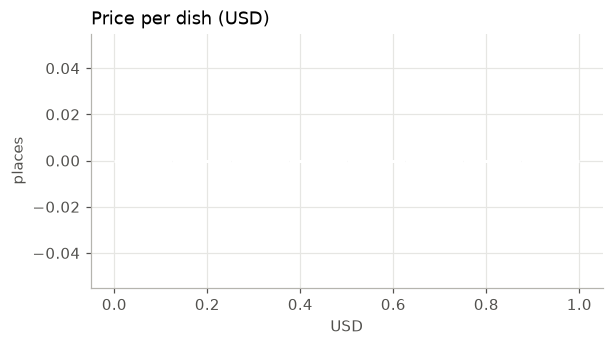

1830 place(s) without a known price


In [21]:
# How many places per area?
display(df["area"].value_counts().rename("places").to_frame())

# Price distribution (rows without a price are left out)
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(df["price_usd"].dropna(), bins=8, color=SERIES[0], edgecolor="white", linewidth=2)
ax.set_title("Price per dish (USD)", loc="left")
ax.set_xlabel("USD")
ax.set_ylabel("places")
plt.show()
print(f"{df['price_usd'].isna().sum()} place(s) without a known price")

### 1d. Online sellers from Telegram channels

**What:** many Phnom Penh sellers post their menu with prices in **Telegram channels**. This step reads recent
posts of the channels you list, finds the lines that contain a price (`Kuy teav $2.5`, `នំបញ្ចុក ៨០០០៛`) and
builds one row per seller for the Google Sheet.

**Two bases for reading a channel** (column `owner_consent` in `data/telegram_channels.csv`)
* `yes`: the owner agreed (you asked, e.g. *"I'm a student building a Phnom Penh food search for my IR course.
  May I list your channel and menu?"*). Dataset rows get `source = telegram`.
* `public-business`: the owner was **not** asked. Use it **only** for the public channel of a **shop or brand**, never for
  an individual or a home cook. Dataset rows get `source = telegram-public`, so your report can say exactly which rows
  had permission and which did not.
* Any other value (or an empty cell) means the channel is **skipped**.

**Rules we follow in both cases**
* **Official API with your own account** (Telethon); public **broadcast channels** only. Groups, private channels and
  invite links are skipped.
* **Only menu lines and post links are kept.** Phone numbers, emails, links and @handles are removed from everything we
  keep, and there are no customer names or comments.
* **Polite reading:** at most `TG_POST_LIMIT` recent posts per channel, with a pause between channels.
* Do not republish the collected data. Check Telegram's API terms and your instructor's rules before you collect.

**Setup (once)**
1. Go to <https://my.telegram.org> → *API development tools*, create an app, put `TG_API_ID` and `TG_API_HASH` in `.env`.
2. Add channels to `data/telegram_channels.csv`: `channel` (e.g. `@shop_channel`), `owner_consent` (`yes` or
   `public-business`), and optionally `area`, `lat`, `lng` (the seller's pickup area) and `notes`.
3. Run the reader cell. **The first time** Telegram asks for your phone number and a login code in VS Code's
   input box. The login is saved in `telegram_reader.session`, which works like a password: it is in
   `.gitignore` and `.dockerignore`, so never share it.

**Output:** `telegram_menu_items.csv` (every menu line found, with a link to its post, for you to check) and
`sheet_import_telegram_sellers.csv` (one row per seller). In Google Sheets, import the seller file with
*Append to current sheet*. Review the rows before your next run.

In [22]:
KHMER_DIGITS = str.maketrans("០១២៣៤៥៦៧៨៩", "0123456789")
PRICE_IN_TEXT_RE = re.compile(
    r"(?P<usd1>\$\s*\d+(?:[.,]\d{1,2})?)"                                   # $2.5
    r"|(?P<usd2>\d+(?:[.,]\d{1,2})?\s*(?:\$|usd\b|ដុល្លារ))"                # 2.5$ / 2.5 usd
    r"|(?P<khr>(?:\d{1,3}(?:[.,]\d{3})+|\d{3,6})\s*(?:៛|រៀល|riel\b|khr\b))",  # 10,000៛ / 8000 riel
    re.I)
NOT_FOOD_RE = re.compile(r"\b(?:delivery|deliver|shipping|fee|discount|promo)\b|ដឹក|សេវា|បញ្ចុះ", re.I)
CONTACT_RE = re.compile(r"https?://\S+|\bt\.me/\S+|\bwww\.\S+|\S+@\S+\.\S+|@\w{3,}")          # links, emails, @handles
PHONE_RE = re.compile(r"(?<![\d.,])(?:\+\d|0)[\d\s()-]{6,}\d(?!\d)")                          # +855 12 345 678, 012-345-678


def strip_contact_info(text: str) -> str:
    """Remove links, emails, @handles and phone numbers (8+ digits) from any text we keep."""
    text = CONTACT_RE.sub(" ", (text or "").translate(KHMER_DIGITS))
    text = PHONE_RE.sub(lambda m: " " if sum(c.isdigit() for c in m.group()) >= 8 else m.group(), text)
    return re.sub(r"\s+", " ", text).strip()


def price_from_text(text):
    """First price in a text line -> (USD, matched text). Khmer digits are converted first."""
    m = PRICE_IN_TEXT_RE.search(text.translate(KHMER_DIGITS))
    if not m:
        return None, ""
    raw = m.group(0)
    if m.group("khr"):
        return khr_to_usd(re.sub(r"[.,]", "", re.match(r"[\d.,]+", m.group("khr")).group())), raw
    return float(re.search(r"\d+(?:[.,]\d{1,2})?", raw).group().replace(",", ".")), raw


def extract_menu_items(post: str) -> list:
    """Menu lines from a seller's post: every line with a price -> {item, price_usd, price_raw}."""
    items = []
    for line in [strip_contact_info(clean_osm_text(x)) for x in (post or "").splitlines() if x.strip()]:
        price, raw = price_from_text(line)
        if price is None or NOT_FOOD_RE.search(line):
            continue
        item = line.translate(KHMER_DIGITS).replace(raw, " ")
        item = re.sub(r"[^\w\s\u1780-\u17FF&'()-]", " ", item)       # drop emoji/bullets, keep Khmer
        item = re.sub(r"\s+", " ", item).strip(" -:()")
        if len(item) >= 2 and re.search(r"[A-Za-z\u1780-\u17FF]", item):
            items.append({"item": item, "price_usd": round(price, 2), "price_raw": raw.strip()})
    return items


# Example posts (invented, to show the parser)
EXAMPLE_POSTS = ["🍜 Today's menu\nKuy teav pork - $2.5\nCurry noodle 2$\nIced coffee: 6,000៛\nDelivery fee $1\nOrder: 012 345 678 @shop_name",
                 "ម៉ឺនុយថ្ងៃនេះ\n• នំបញ្ចុកសម្លការី ៨០០០៛\n• គុយទាវ ១០.០០០ រៀល\nដឹកជញ្ជូនឥតគិតថ្លៃ"]
display(pd.DataFrame([it for post in EXAMPLE_POSTS for it in extract_menu_items(post)]))
print(strip_contact_info("Call +855 12 345 678 or 096-123-4567, t.me/shop, @shop_name, a@b.com. Price 12000 15000៛"))

,item,price_usd,price_raw
0,Kuy teav pork,2.50,$2.5
1,Curry noodle,2.00,2$
2,Iced coffee,1.46,"6,000៛"
3,នំបញ្ចុកសម្លការី,1.95,8000៛
4,គុយទាវ,2.44,10.000 រៀល


Call or , , Price 12000 15000៛


In [23]:
TG_CHANNELS_PATH = DATA_DIR / "telegram_channels.csv"
if not TG_CHANNELS_PATH.exists():
    pd.DataFrame(columns=["channel", "owner_consent", "area", "lat", "lng", "notes"]).to_csv(TG_CHANNELS_PATH, index=False)
    print("created data/telegram_channels.csv (add the channels to read; owner_consent = yes or public-business)")
SOURCE_BY_BASIS = {"yes": "telegram", "public-business": "telegram-public"}      # value in `source` of the dataset
tg_channels = pd.read_csv(TG_CHANNELS_PATH, dtype={"channel": str, "owner_consent": str, "area": str})
tg_channels["area"] = tg_channels["area"].fillna("")
tg_channels["owner_consent"] = tg_channels["owner_consent"].fillna("").str.strip().str.lower()
readable = tg_channels[tg_channels["owner_consent"].isin(SOURCE_BY_BASIS) & tg_channels["channel"].notna()]
print(f"{len(tg_channels)} channel(s) listed: {(readable['owner_consent'] == 'yes').sum()} with owner permission, "
      f"{(readable['owner_consent'] == 'public-business').sum()} public business channel(s) read without asking")
if len(tg_channels) > len(readable):
    print(f"⚠️ {len(tg_channels) - len(readable)} row(s) skipped: owner_consent must be 'yes' or 'public-business'")

0 channel(s) listed: 0 with owner permission, 0 public business channel(s) read without asking


In [24]:
async def read_seller_channels(client, channels: pd.DataFrame, limit=TG_POST_LIMIT):
    """Read recent posts of the listed *broadcast* channels. Returns (menu items, channel infos)."""
    items, infos = [], []
    for row in channels.itertuples():
        username = re.sub(r"^(?:https?://)?t\.me/", "", row.channel.strip()).strip("/@").split("?")[0]
        if username.startswith(("+", "joinchat")):
            print(f"⚠️ {row.channel}: private invite links are not supported, skipped")
            continue
        try:
            entity = await client.get_entity(username)
        except Exception as e:
            print(f"⚠️ @{username}: cannot open ({type(e).__name__}), skipped")
            continue
        if not getattr(entity, "broadcast", False):        # groups contain private people's messages
            print(f"⚠️ @{username}: not a broadcast channel, skipped")
            continue
        n_posts = 0
        async for msg in client.iter_messages(entity, limit=limit):
            if not msg.message:
                continue
            n_posts += 1
            for it in extract_menu_items(msg.message):
                items.append({"channel": username, "basis": row.owner_consent, "url": f"https://t.me/{username}/{msg.id}",
                              "date": msg.date.date().isoformat(), **it})
        about = ""
        try:
            from telethon.tl.functions.channels import GetFullChannelRequest
            about = (await client(GetFullChannelRequest(entity))).full_chat.about or ""
        except Exception:
            pass
        infos.append({"channel": username, "title": entity.title, "about": about, "posts_read": n_posts,
                      "basis": row.owner_consent, "area": row.area, "lat": row.lat, "lng": row.lng})
        print(f"@{username} ({row.owner_consent}): {n_posts} posts read, "
              f"{sum(i['channel'] == username for i in items)} menu items")
        await asyncio.sleep(1.5)                           # be polite: pause between channels
    return pd.DataFrame(items), pd.DataFrame(infos)


def seller_rows(items: pd.DataFrame, infos: pd.DataFrame) -> pd.DataFrame:
    """One row per seller in our 18-column format (main dishes = most frequent menu items)."""
    rows, today = [], datetime.now(TZ).date().isoformat()
    for info in infos.itertuples():
        its = items[items["channel"] == info.channel] if len(items) else items
        names = its["item"].str.lower().value_counts().index.tolist() if len(its) else []
        km = [n for n in names if KHMER_RE.search(n)][:5]
        en = [n for n in names if not KHMER_RE.search(n)][:5]
        about = strip_contact_info(clean_osm_text(info.about))[:300]
        rows.append({
            "id": f"tg-{info.channel.lower()}", "name": strip_contact_info(clean_osm_text(info.title)),
            "dish_en": "; ".join(en), "dish_km": " ".join(km),
            "description": about or f"Online food seller on Telegram ({len(its)} menu items in recent posts).",
            "tags": "online;delivery;telegram",
            "price_usd": round(float(its["price_usd"].median()), 2) if len(its) else "",
            "area": info.area, "lat": info.lat, "lng": info.lng, "rating": "", "open_hour": "", "close_hour": "",
            "source": SOURCE_BY_BASIS.get(info.basis, "telegram-public"), "source_url": f"https://t.me/{info.channel}", "date": today,
            "image_path": "", "phone_public": "",           # contact details only if the seller adds them
        })
    return pd.DataFrame(rows, columns=ALL_COLUMNS)

In [25]:
# Run the reader (needs TG_API_ID / TG_API_HASH and at least one channel in the list)
TG_SESSION = ROOT / "telegram_reader"            # Telethon adds .session (a secret: never share it)
if not (TG_API_ID and TG_API_HASH):
    print("⏭️ TG_API_ID / TG_API_HASH missing in .env: skipping the Telegram reader.")
elif readable.empty:
    print("⏭️ No channel with owner_consent = yes / public-business in data/telegram_channels.csv: nothing to read.")
else:
    from telethon import TelegramClient
    client = None
    try:
        client = TelegramClient(str(TG_SESSION), int(TG_API_ID), TG_API_HASH)
        await client.start()                     # first time: phone number + login code
        tg_items, tg_infos = await read_seller_channels(client, readable)
        tg_items.to_csv(ROOT / "telegram_menu_items.csv", index=False)
        tg_sellers = seller_rows(tg_items, tg_infos)
        tg_sellers.to_csv(ROOT / "sheet_import_telegram_sellers.csv", index=False)
        print(f"✅ {len(tg_items)} menu items -> telegram_menu_items.csv, "
              f"{len(tg_sellers)} sellers -> sheet_import_telegram_sellers.csv")
        display(tg_sellers[["id", "name", "dish_en", "dish_km", "price_usd", "area"]])
    except Exception as e:
        print(f"❌ Telegram reader failed: {type(e).__name__}: {str(e)[:150]}")
    finally:
        if client is not None:
            await client.disconnect()

⏭️ No channel with owner_consent = yes / public-business in data/telegram_channels.csv: nothing to read.


## 2. Evaluation set

**What:** a list of test queries, each with the ids of the places that *should* be found. Mix English, Khmer,
typos (`carry noodle`, `kuytiew`), meaning-only queries (`something sweet`) and conditions (`cheap`, `open late`).

**Why:** without a test set we can only *feel* whether search got better. With it we can **measure** it:
* **Recall@5**: the share of the relevant places that appear in the top 5
* **MRR**: 1 / rank of the first relevant result (1.0 = the first result is relevant). We compute it on the top 5 (MRR@5).
* **nDCG@5**: rewards relevant results that are ranked *higher* (1.0 = perfect order)

**Your job:** no ready-made test set ships with this project, because the labels must be checked by a person who
knows the places. Create `data/eval/queries.csv` (or a tab of your Google Sheet, `SHEET_QUERIES_URL`) with the columns
`query`, `relevant_ids` (ids from `restaurants.csv`, separated by `;`), `lang`, `kind`. Aim for 30–50 queries.
Until it has rows, the evaluation cells are skipped and the rest of the notebook still runs.

In [26]:
QUERIES_PATH = EVAL_DIR / "queries.csv"
EVAL_COLUMNS = ["query", "relevant_ids", "lang", "kind"]
eval_df = None
if SHEET_QUERIES_URL:                        # optional sheet tab with columns query, relevant_ids (lang, kind)
    eval_df = load_from_sheet(SHEET_QUERIES_URL, ["query", "relevant_ids"], {"relevant_ids": str})
    if eval_df is not None:
        eval_df.to_csv(QUERIES_PATH, index=False)
        print(f"Downloaded {len(eval_df)} queries from Google Sheets -> snapshot saved to data/eval/queries.csv")
if eval_df is None and QUERIES_PATH.exists():
    eval_df = pd.read_csv(QUERIES_PATH, dtype={"relevant_ids": str})
    print(f"Loaded {len(eval_df)} queries from data/eval/queries.csv")
elif eval_df is None:
    eval_df = pd.DataFrame(columns=EVAL_COLUMNS)
    eval_df.to_csv(QUERIES_PATH, index=False)
    print("Created an empty data/eval/queries.csv (header only): add your test queries there.")
for col in ("lang", "kind"):
    if col not in eval_df.columns:
        eval_df[col] = ""
eval_df["relevant"] = eval_df["relevant_ids"].fillna("").astype(str).str.split(";").map(
    lambda ids: {i.strip() for i in ids if i.strip()})

# Keep only queries that point at ids that exist in the data
known_ids = set(df["id"])
unknown = sorted(set().union(*eval_df["relevant"]) - known_ids)
if unknown:
    print(f"⚠️ {len(unknown)} relevant id(s) are not in the data: {unknown[:10]}. Check data/eval/queries.csv.")
usable = eval_df["relevant"].map(lambda ids: bool(ids & known_ids)).astype(bool)
eval_df = eval_df[usable].reset_index(drop=True)
HAS_EVAL = len(eval_df) > 0
if HAS_EVAL:
    print(f"{len(eval_df)} usable evaluation queries")
    display(eval_df[["query", "relevant_ids", "lang", "kind"]].head(8))
else:
    print("📋 No evaluation queries yet: the evaluation cells below are skipped (see the note above).")

Loaded 0 queries from data/eval/queries.csv
📋 No evaluation queries yet: the evaluation cells below are skipped (see the note above).


In [27]:
def recall_at_k(ranked, relevant, k=5) -> float:
    return len(set(ranked[:k]) & set(relevant)) / len(relevant) if relevant else 0.0


def mrr(ranked, relevant) -> float:
    """Reciprocal rank of the first relevant result (averaged over queries = MRR)."""
    for rank, doc in enumerate(ranked, 1):
        if doc in relevant:
            return 1.0 / rank
    return 0.0


def ndcg_at_k(ranked, relevant, k=5) -> float:
    """Binary-relevance nDCG: DCG of our ranking / DCG of the perfect ranking."""
    dcg = sum(1 / math.log2(rank + 1) for rank, doc in enumerate(ranked[:k], 1) if doc in relevant)
    ideal = sum(1 / math.log2(rank + 1) for rank in range(1, min(len(relevant), k) + 1))
    return dcg / ideal if ideal else 0.0

In [28]:
# Toy test: 5 ranked docs, relevant = b, e and z (z was never retrieved)
ranked, relevant = ["a", "b", "c", "d", "e"], {"b", "e", "z"}
assert recall_at_k(ranked, relevant, 5) == 2 / 3
assert recall_at_k(ranked, relevant, 1) == 0.0
assert mrr(ranked, relevant) == 0.5
expected = (1 / math.log2(3) + 1 / math.log2(6)) / (1 + 1 / math.log2(3) + 1 / math.log2(4))
assert abs(ndcg_at_k(ranked, relevant, 5) - expected) < 1e-9
assert ndcg_at_k(["b", "e", "z"], relevant, 3) == 1.0

# Cross-check nDCG against scikit-learn (same case without the missing doc z)
from sklearn.metrics import ndcg_score
sk = ndcg_score([[0, 1, 0, 0, 1]], [[5, 4, 3, 2, 1]], k=5)
assert abs(ndcg_at_k(ranked, {"b", "e"}, 5) - sk) < 1e-9
print("✅ metric tests passed")

✅ metric tests passed


In [29]:
RESULTS, PER_QUERY = {}, {}     # method name -> mean metrics / per-query table


def evaluate(search_fn, queries=None, k=5):
    """search_fn(query, k) -> ranked list of ids. Returns (mean metrics, per-query table)."""
    queries = eval_df if queries is None else queries
    rows = []
    for q, rel in zip(queries["query"], queries["relevant"]):
        ranked = search_fn(q, k)
        rows.append({"query": q, f"Recall@{k}": recall_at_k(ranked, rel, k),
                     "MRR": mrr(ranked[:k], rel), f"nDCG@{k}": ndcg_at_k(ranked, rel, k)})
    per_query = pd.DataFrame(rows)
    return per_query.drop(columns="query").mean().round(3).to_dict(), per_query

## 3. Baseline: BM25 + fuzzy matching

**What:** **BM25** scores a document by how many query words it contains, giving more weight to rare
words and less to very long documents. It searches over name, dish (EN + KM), description and tags.

**Tokenizing Khmer:** Khmer is written **without spaces between words**, so splitting on spaces does
not work. As a simple default we cut Khmer text into **character 2-grams and 3-grams**
(`គុយទាវ` → `គុ, ុយ, យទ, …`), so a query matches documents that share these pieces. A real
Khmer word segmenter would be better (see *next steps*).

**Typos:** an English query word that is not in the vocabulary is replaced by the closest vocabulary word
with **rapidfuzz** (`carry` → `curry`). If BM25 still finds nothing, a **fuzzy fallback** compares the query
with the place and dish names character by character (`kuytiew` ≈ `kuyteav`).

In [30]:
def tokenize(text) -> list:
    """English words (with light plural stemming) + Khmer character 2/3-grams."""
    text = normalize_text(text)
    tokens = [w[:-1] if len(w) > 3 and w.endswith("s") and not w.endswith("ss") else w
              for w in WORD_RE.findall(text)]
    for run in KHMER_RE.findall(text):          # Khmer is written without spaces
        if len(run) < 2:
            tokens.append(run)
        for n in (2, 3):
            tokens += [run[i:i + n] for i in range(len(run) - n + 1)]
    return tokens


print(tokenize("Curry Noodles នំបញ្ចុក"))

['curry', 'noodle', 'នំ', 'ំប', 'បញ', 'ញ្', '្ច', 'ចុ', 'ុក', 'នំប', 'ំបញ', 'បញ្', 'ញ្ច', '្ចុ', 'ចុក']


In [31]:
def build_bm25(d: pd.DataFrame):
    """BM25 index over the combined text + the English vocabulary (for typo fixing)."""
    corpus = [tokenize(t) for t in d["doc_text"]]
    vocab = sorted({t for doc in corpus for t in doc if WORD_RE.fullmatch(t)})
    return BM25Okapi(corpus), vocab


bm25, BM25_VOCAB = build_bm25(df)
print(f"BM25 index: {len(df)} documents, {len(BM25_VOCAB)} English words in the vocabulary")

BM25 index: 1830 documents, 1922 English words in the vocabulary


In [32]:
def correct_tokens(tokens, vocab, cutoff=None):
    """Replace unknown English words by the closest vocabulary word ('carry' -> 'curry')."""
    vocab_set, fixed = set(vocab), []
    for t in tokens:
        if t in vocab_set or len(t) < 4 or not WORD_RE.fullmatch(t):
            fixed.append(t)
            continue
        match = process.extractOne(t, vocab, scorer=fuzz.ratio, score_cutoff=cutoff or TYPO_CUTOFF)
        fixed.append(match[0] if match else t)
    return fixed


def fuzzy_scores(query, d: pd.DataFrame) -> np.ndarray:
    """Typo fallback: fuzzy match the query against names and dish names (spaces removed)."""
    q = normalize_text(query).replace(" ", "")
    fields = (d["name"] + " " + d["dish_en"] + " " + d["dish_km"]).map(normalize_text).str.replace(" ", "")
    scores = np.array([fuzz.partial_ratio(q, f) for f in fields]) / 100
    scores[scores < FUZZY_MIN] = 0.0
    return scores


print(correct_tokens(tokenize("carry noodle"), BM25_VOCAB))

['curry', 'noodle']


In [33]:
def bm25_scores(query):
    """Raw BM25 score per row of df (+ which method produced them)."""
    tokens = tokenize(query)
    if not tokens:
        return np.zeros(len(df)), "empty"
    fixed = correct_tokens(tokens, BM25_VOCAB)
    scores = np.asarray(bm25.get_scores(fixed), dtype=float)
    method = "bm25+typo-fix" if fixed != tokens else "bm25"
    if scores.max() <= 0:                    # no keyword hit at all -> fuzzy fallback
        scores, method = fuzzy_scores(query, df), "fuzzy"
    return scores, method


def bm25_search(query, k=TOP_K) -> pd.DataFrame:
    scores, method = bm25_scores(query)
    order = [i for i in np.argsort(-scores, kind="stable") if scores[i] > 0][:k]
    out = df.iloc[order][["id", "name", "dish_en", "dish_km", "price_usd", "area"]].copy()
    out["score"] = scores[order].round(3)
    out["method"] = method
    return out.reset_index(drop=True)

In [34]:
DEMO_QUERIES = ["curry noodle", "carry noodle", "នំបញ្ចុក"]
for q in DEMO_QUERIES:
    print(f"🔎 {q}")
    display(bm25_search(q))

🔎 curry noodle


,id,name,dish_en,dish_km,price_usd,area,score,method
0,osm-n5586787217,Khmer curry stall,,,NaN,Chamkar Mon,7.584,bm25
1,osm-n4586489994,Malop Chat Toul Tom Poung,noodles; local,មី,NaN,Chamkar Mon,5.510,bm25
2,osm-n4178059189,Marugame Udon,noodles,មី,NaN,Boeng Keng Kang,5.510,bm25
3,osm-n5506162821,Phka Romchong Coffee & Noodle Shop,breakfast; noodles; coffee,មី កាហ្វេ,NaN,Boeng Keng Kang,5.421,bm25
4,osm-n5053753420,red curry,,,NaN,Sen Sok,5.355,bm25


🔎 carry noodle


,id,name,dish_en,dish_km,price_usd,area,score,method
0,osm-n5586787217,Khmer curry stall,,,NaN,Chamkar Mon,7.584,bm25+typo-fix
1,osm-n4586489994,Malop Chat Toul Tom Poung,noodles; local,មី,NaN,Chamkar Mon,5.510,bm25+typo-fix
2,osm-n4178059189,Marugame Udon,noodles,មី,NaN,Boeng Keng Kang,5.510,bm25+typo-fix
3,osm-n5506162821,Phka Romchong Coffee & Noodle Shop,breakfast; noodles; coffee,មី កាហ្វេ,NaN,Boeng Keng Kang,5.421,bm25+typo-fix
4,osm-n5053753420,red curry,,,NaN,Sen Sok,5.355,bm25+typo-fix


🔎 នំបញ្ចុក


,id,name,dish_en,dish_km,price_usd,area,score,method
0,osm-n10292468209,នំបញ្ចុក482,asian,,NaN,Chamkar Mon,65.476,bm25
1,osm-n4861669721,បបរ នំបញ្ចុក,,,NaN,Toul Kork,65.476,bm25
2,osm-n5221752969,Bún Riêu Cua,,,NaN,Daun Penh,51.470,bm25
3,osm-n6070457911,នំបញ្ចុកសាច់ចិញ្រ្ចាំ,,,NaN,Boeng Keng Kang,47.935,bm25
4,osm-n5172810247,Delicious Khmer Noodles,,,NaN,Chbar Ampov,44.064,bm25


In [35]:
if HAS_EVAL:
    RESULTS["BM25 + fuzzy"], PER_QUERY["BM25 + fuzzy"] = evaluate(lambda q, k: bm25_search(q, k)["id"].tolist())
    print(RESULTS["BM25 + fuzzy"])
else:
    print("⏭️ skipped: no evaluation queries yet (see section 2)")

⏭️ skipped: no evaluation queries yet (see section 2)


## 4. Semantic search: embeddings + ChromaDB

**What:** a **multilingual sentence-embedding model** turns each place's text into a vector, so texts with similar
*meaning* get nearby vectors, even across languages (`dessert` ≈ `បង្អែម` ≈ `something sweet`). The vectors
are stored in **ChromaDB** (a local vector database in `chroma_db/`) together with metadata (name, area, price, …).

**Model:** `paraphrase-multilingual-MiniLM-L12-v2` by default (small and fast, 50+ languages).
To try a stronger model, set `EMBED_MODEL=BAAI/bge-m3` in `.env`. Each model gets its **own collection**, so
vector sizes never mix.

**Idempotent:** building uses `upsert` (insert or update by id) and deletes ids that left the CSV, so
re-running the cell never creates duplicates.

In [36]:
from sentence_transformers import SentenceTransformer
import chromadb
from chromadb.config import Settings

embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
print(f"Loaded {EMBED_MODEL} on {DEVICE}, vector size {embedder.get_sentence_embedding_dimension()}")

W1102 14:40:42.952000 13581 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6926.81it/s]

Loaded paraphrase-multilingual-MiniLM-L12-v2 on mps, vector size 384


In [37]:
def embed_texts(texts) -> np.ndarray:
    """Unit-length sentence embeddings (so dot product = cosine similarity)."""
    return embedder.encode(list(texts), batch_size=32, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=False)


@lru_cache(maxsize=2048)
def embed_query(query: str) -> np.ndarray:
    return embed_texts([normalize_text(query)])[0]


def open_chroma():
    return chromadb.PersistentClient(path=str(CHROMA_DIR), settings=Settings(anonymized_telemetry=False))


def get_text_collection(client):
    # one collection per embedding model, so switching EMBED_MODEL never mixes vector sizes
    name = ("food_text_" + re.sub(r"[^a-z0-9]+", "_", EMBED_MODEL.lower()))[:60].strip("_")
    return client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})


def row_metadata(r) -> dict:
    meta = {"name": r["name"], "area": r["area"], "source": r["source"]}
    for c in ["price_usd", "rating", "lat", "lng", "open_hour", "close_hour"]:
        if pd.notna(r[c]):                   # Chroma metadata cannot hold None/NaN
            meta[c] = float(r[c])
    return meta


def build_text_index(d: pd.DataFrame, collection) -> int:
    """Upsert every row (safe to re-run) and delete ids that are no longer in the CSV."""
    collection.upsert(ids=d["id"].tolist(),
                      embeddings=embed_texts(d["doc_text"]).tolist(),
                      documents=d["doc_text"].tolist(),
                      metadatas=[row_metadata(r) for _, r in d.iterrows()])
    stale = set(collection.get(include=[])["ids"]) - set(d["id"])
    if stale:
        collection.delete(ids=sorted(stale))
    return collection.count()


chroma = open_chroma()
text_col = get_text_collection(chroma)
print(f"Collection {text_col.name!r}: {build_text_index(df, text_col)} vectors (re-run = same count)")

Collection 'food_text_paraphrase_multilingual_minilm_l12_v2': 1830 vectors (re-run = same count)


In [38]:
def embedding_scores(query) -> np.ndarray:
    """Cosine similarity per row of df (rows beyond EMBED_CANDIDATES, if any, get 0)."""
    n = min(EMBED_CANDIDATES, text_col.count())
    res = text_col.query(query_embeddings=[embed_query(query).tolist()], n_results=n,
                         include=["distances"])
    sims = {i: 1.0 - dist for i, dist in zip(res["ids"][0], res["distances"][0])}
    return np.array([sims.get(i, 0.0) for i in df["id"]])


def embedding_search(query, k=TOP_K) -> pd.DataFrame:
    scores = embedding_scores(query)
    order = np.argsort(-scores, kind="stable")[:k]
    out = df.iloc[order][["id", "name", "dish_en", "dish_km", "price_usd", "area"]].copy()
    out["score"] = scores[order].round(3)
    return out.reset_index(drop=True)

In [39]:
for q in DEMO_QUERIES:
    print(f"🔎 {q}")
    display(embedding_search(q))

🔎 curry noodle


,id,name,dish_en,dish_km,price_usd,area,score
0,osm-n7214995387,Curry pot,indian food,ម្ហូបឥណ្ឌា,NaN,Chamkar Mon,0.625
1,osm-n4253751389,Heng Heng - Fried 'silver needle' noodles,,,NaN,Daun Penh,0.612
2,osm-n5172810247,Delicious Khmer Noodles,,,NaN,Chbar Ampov,0.594
3,osm-n4586509693,$1 noodles,local,,NaN,Chamkar Mon,0.592
4,osm-n13080663893,ស៊ុបនឹងសាច់អាំង,bbq; soup,សាច់អាំង,NaN,Dangkao,0.591


🔎 carry noodle


,id,name,dish_en,dish_km,price_usd,area,score
0,osm-n4178059189,Marugame Udon,noodles,មី,NaN,Boeng Keng Kang,0.552
1,osm-n4586509693,$1 noodles,local,,NaN,Chamkar Mon,0.487
2,osm-n4586489994,Malop Chat Toul Tom Poung,noodles; local,មី,NaN,Chamkar Mon,0.466
3,osm-n5542106606,Seoul 7 Level Spicy Soup,noodles; korean food,មី ម្ហូបកូរ៉េ,NaN,Russey Keo,0.463
4,osm-n4711644591,Spicy Noodle,,,NaN,Daun Penh,0.463


🔎 នំបញ្ចុក


,id,name,dish_en,dish_km,price_usd,area,score
0,osm-n13084021612,នំបញ្ចុកប្រហើរ បាយស្រូបសាច់ជ្រូក បបរសាច់ត្រីសា...,,,NaN,Dangkao,0.573
1,osm-n9795791170,The Vine,,,NaN,Daun Penh,0.515
2,osm-n5909426879,Dim Sum Emperors,chinese food,ម្ហូបចិន,NaN,Toul Kork,0.514
3,osm-n5336742121,Yey Ett Soup,,,NaN,Mean Chey,0.502
4,osm-n7942731726,Sen Sok Restaurant,,,NaN,Sen Sok,0.500


In [40]:
if HAS_EVAL:
    RESULTS["Embeddings"], PER_QUERY["Embeddings"] = evaluate(lambda q, k: embedding_search(q, k)["id"].tolist())
    print(RESULTS["Embeddings"])
else:
    print("⏭️ skipped: no evaluation queries yet (see section 2)")

⏭️ skipped: no evaluation queries yet (see section 2)


## 5. Hybrid search + geo + filters

**What:** combine both signals. BM25 is good at exact words and names; embeddings are good at meaning and
cross-language matches. Their scores are on different scales, so each is **min-max normalized to 0..1** first:

`final = w · embed + (1 − w) · bm25 + rating_boost + distance_score`  (w = `HYBRID_WEIGHT`)

* `rating_boost = 0.05 · rating / 5` is a small tie-breaker for good places
* `distance_score = 0.15 / (1 + km)`, used only when the user shares a location (**Haversine** distance)
* **filters** parsed from the query text: `under $3` / `ក្រោម 5 ដុល្លារ` → max price, `cheap` / `ថោក` → ≤ $3,
  `open now` (Phnom Penh time), `open late` (closes ≥ 23:00 or after midnight), `top rated` → rating ≥ 4.5, area names
* rows that match neither by keyword nor by meaning (cosine < `MIN_EMBED_SIM`) are dropped, so an unrelated query like "car repair" returns *nothing*
  instead of random places. The threshold 0.45 was picked by looking at a few queries with the default MiniLM model
  (unrelated queries such as *car repair* score close to 0, real meaning matches are ≥ 0.45 on the few queries I checked). **Re-check it if you change `EMBED_MODEL`.**

In [41]:
def haversine_km(lat1, lng1, lat2, lng2):
    """Great-circle distance in km (works on numbers or numpy/pandas arrays)."""
    lat1, lng1, lat2, lng2 = (np.radians(np.asarray(x, dtype=float)) for x in (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def minmax(x) -> np.ndarray:
    """Scale to 0..1 so BM25 and cosine scores become comparable."""
    x = np.asarray(x, dtype=float)
    lo, hi = x.min(), x.max()
    return np.zeros_like(x) if hi - lo < 1e-12 else (x - lo) / (hi - lo)


# Sanity check: Royal Palace area -> BKK1 should be about 1.4 km
print(f"{float(haversine_km(11.5640, 104.9310, 11.5530, 104.9248)):.2f} km")

1.40 km


In [42]:
PRICE_RE = re.compile(r"(?:under|below|less than|cheaper than|max|<|ក្រោម|តិចជាង)\s*\$?\s*(\d+(?:\.\d+)?)"
                      r"\s*(\$|usd|dollars?|ដុល្លារ|khr|riel|៛|រៀល)?")
FILTER_PHRASES = [  # (regex, filter name, value)
    (r"\bopen (?:right )?now\b|បើកឥឡូវ", "open_now", True),
    (r"\bopen late\b|\blate night\b|\blate\b|បើកយប់|យប់ជ្រៅ", "open_late", True),
    (r"\bcheap\b|\bbudget\b|ថោក", "max_price", CHEAP_MAX_USD),
    (r"\btop rated\b|\bbest rated\b", "min_rating", 4.5),
]


def parse_query_filters(query):
    """Pull conditions out of the query text. Returns (remaining query, filters dict)."""
    q, f = normalize_text(query), {}
    m = PRICE_RE.search(q)
    if m:
        amount, unit = float(m.group(1)), (m.group(2) or "$")
        f["max_price"] = khr_to_usd(amount) if unit in ("khr", "riel", "៛", "រៀល") else amount
        q = q.replace(m.group(0), " ")
    for pattern, key, value in FILTER_PHRASES:
        if re.search(pattern, q):
            f.setdefault(key, value)
            q = re.sub(pattern, " ", q)
    for area in sorted(df["area_key"].unique(), key=len, reverse=True):
        if area and area in q:
            f["area"] = area
            q = q.replace(area, " ")
            break
    return re.sub(r"\s+", " ", q).strip(), f


def is_open_at(open_h, close_h, hour) -> bool:
    """Opening hours may cross midnight (e.g. 18 -> 2). Unknown hours = not open."""
    if pd.isna(open_h) or pd.isna(close_h):
        return False
    open_h, close_h = float(open_h), float(close_h) % 24
    if open_h == close_h:
        return True                          # open 24 hours
    if open_h < close_h:
        return open_h <= hour < close_h
    return hour >= open_h or hour < close_h


def closes_late(open_h, close_h) -> bool:
    if pd.isna(open_h) or pd.isna(close_h):
        return False
    return close_h >= LATE_HOUR or close_h < open_h


def apply_filters(d: pd.DataFrame, f: dict, now=None) -> np.ndarray:
    """Boolean mask. Rows with an unknown price never pass a price filter."""
    mask = np.ones(len(d), dtype=bool)
    if f.get("max_price") is not None:
        mask &= d["price_usd"].le(f["max_price"]).to_numpy()
    if f.get("min_rating") is not None:
        mask &= d["rating"].ge(f["min_rating"]).to_numpy()
    if f.get("area"):
        mask &= d["area_key"].eq(normalize_text(f["area"])).to_numpy()
    if f.get("open_now"):
        now = now or datetime.now(TZ)
        hour = now.hour + now.minute / 60
        mask &= np.array([is_open_at(o, c, hour) for o, c in zip(d["open_hour"], d["close_hour"])], dtype=bool)
    if f.get("open_late"):
        mask &= np.array([closes_late(o, c) for o, c in zip(d["open_hour"], d["close_hour"])], dtype=bool)
    return mask


for q in ["bbq under $5", "cheap kuy teav", "noodles open late", "korean in toul kork", "គុយទាវ ថោក", "coffee open now"]:
    print(f"{q!r:22} -> {parse_query_filters(q)}")

'bbq under $5'         -> ('bbq', {'max_price': 5.0})
'cheap kuy teav'       -> ('kuy teav', {'max_price': 3.0})
'noodles open late'    -> ('noodles', {'open_late': True})
'korean in toul kork'  -> ('korean in', {'area': 'toul kork'})
'គុយទាវ ថោក'           -> ('គុយទាវ', {'max_price': 3.0})
'coffee open now'      -> ('coffee', {'open_now': True})


In [43]:
def hybrid_search(query, k=TOP_K, user_loc=None, weight=None, filters=None,
                  use_query_filters=True, now=None) -> pd.DataFrame:
    """BM25 + embeddings + rating + distance, after filters. user_loc = (lat, lng)."""
    weight = HYBRID_WEIGHT if weight is None else weight
    text, parsed = parse_query_filters(query) if use_query_filters else (normalize_text(query), {})
    flt = {**parsed, **(filters or {})}
    out = df.copy()
    if text:
        bm, method = bm25_scores(text)
        em = embedding_scores(text)
    else:                                    # query was only conditions, e.g. "open now"
        bm, em, method = np.zeros(len(df)), np.zeros(len(df)), "filters-only"
    out["bm25"], out["embed"] = minmax(bm), minmax(em)
    out["rating_boost"] = RATING_BOOST * out["rating"].fillna(0) / 5
    out["distance_km"], out["distance"] = np.nan, 0.0
    if user_loc:
        out["distance_km"] = haversine_km(user_loc[0], user_loc[1], out["lat"], out["lng"])
        out["distance"] = DISTANCE_WEIGHT / (1 + out["distance_km"].fillna(1e6))
    out["final"] = weight * out["embed"] + (1 - weight) * out["bm25"] + out["rating_boost"] + out["distance"]
    keep = apply_filters(out, flt, now)
    if text:                                 # drop rows that match neither by keyword nor by meaning
        keep &= (bm > 0) | (em >= MIN_EMBED_SIM)
    out = out[keep].sort_values("final", ascending=False, kind="stable").head(k).reset_index(drop=True)
    out.attrs.update(filters=flt, method=method, query_text=text)
    return out


def get_rows(ids) -> pd.DataFrame:
    """Rows for the given ids, in that order (unknown ids are skipped)."""
    known = set(df["id"])
    ids = [i for i in dict.fromkeys(ids) if i in known]
    return df.set_index("id").loc[ids].reset_index()

In [44]:
SHOW = ["id", "name", "dish_en", "price_usd", "rating", "bm25", "embed", "distance", "final"]
for q in DEMO_QUERIES:
    res = hybrid_search(q)
    print(f"🔎 {q}   (keyword method: {res.attrs['method']})")
    display(res[SHOW].round(3))

🔎 curry noodle   (keyword method: bm25)


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-n5586787217,Khmer curry stall,,NaN,NaN,1.000,0.767,0.0,0.883
1,osm-n7214995387,Curry pot,indian food,NaN,NaN,0.669,1.000,0.0,0.835
2,osm-n4586489994,Malop Chat Toul Tom Poung,noodles; local,NaN,NaN,0.727,0.929,0.0,0.828
3,osm-n4178059189,Marugame Udon,noodles,NaN,NaN,0.727,0.893,0.0,0.810
4,osm-n5053753420,red curry,,NaN,NaN,0.706,0.897,0.0,0.801


🔎 carry noodle   (keyword method: bm25+typo-fix)


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-n4178059189,Marugame Udon,noodles,NaN,NaN,0.727,1.000,0.0,0.863
1,osm-n4586489994,Malop Chat Toul Tom Poung,noodles; local,NaN,NaN,0.727,0.845,0.0,0.786
2,osm-n5586787217,Khmer curry stall,,NaN,NaN,1.000,0.519,0.0,0.760
3,osm-n4711644591,Spicy Noodle,,NaN,NaN,0.642,0.838,0.0,0.740
4,osm-n4586509693,$1 noodles,local,NaN,NaN,0.580,0.882,0.0,0.731


🔎 នំបញ្ចុក   (keyword method: bm25)


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-n4861669721,បបរ នំបញ្ចុក,,NaN,NaN,1.000,0.739,0.0,0.870
1,osm-n10292468209,នំបញ្ចុក482,asian,NaN,NaN,1.000,0.645,0.0,0.822
2,osm-n5221752969,Bún Riêu Cua,,NaN,NaN,0.786,0.677,0.0,0.731
3,osm-n5172810247,Delicious Khmer Noodles,,NaN,NaN,0.673,0.736,0.0,0.705
4,osm-n6070457911,នំបញ្ចុកសាច់ចិញ្រ្ចាំ,,NaN,NaN,0.732,0.633,0.0,0.682


In [45]:
# Filters and location
now = datetime.now(TZ)
print("Phnom Penh time now:", now.strftime("%H:%M"))
for q in ["korean bbq", "coffee open now"]:
    res = hybrid_search(q)
    print(f"🔎 {q}   filters={res.attrs['filters']}")
    display(res[SHOW].round(3))

INDEPENDENCE_MONUMENT = (11.5564, 104.9282)
res = hybrid_search("iced coffee", user_loc=INDEPENDENCE_MONUMENT)
print("🔎 iced coffee, near Independence Monument")
display(res[SHOW + ["distance_km"]].round(3))
print(f"🔎 car repair -> {len(hybrid_search('car repair'))} results (0 = the bot answers 'nothing matches')")

Phnom Penh time now: 14:40
🔎 korean bbq   filters={}


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-n11304262061,Misigga BBQ - Korean BBQ & Hot Pot,korean food,NaN,NaN,1.000,1.000,0.0,1.000
1,osm-n6337621896,Korean,,NaN,NaN,0.525,0.936,0.0,0.731
2,osm-n4756285724,JARU,korean food,NaN,NaN,0.497,0.963,0.0,0.730
3,osm-n6335609492,Korean bbq,,NaN,NaN,0.595,0.865,0.0,0.730
4,osm-n7936477385,Hana Buffet BBQ&Soup (Olympic),korean food; thai food,NaN,NaN,0.634,0.822,0.0,0.728


🔎 coffee open now   filters={'open_now': True}


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-w188369597,Well Coffee,"coffee, cake sandwich",NaN,NaN,1.000,0.900,0.0,0.950
1,osm-n12422098894,Starbucks,coffee; tea,NaN,NaN,0.905,0.929,0.0,0.917
2,osm-n11245003537,Tube Coffee Riverside,coffee,NaN,NaN,0.935,0.894,0.0,0.915
3,osm-n13607375002,1999 Coffee,coffee,NaN,NaN,0.935,0.837,0.0,0.886
4,osm-n4209266194,Cozy Coffee,coffee,NaN,NaN,0.935,0.817,0.0,0.876


🔎 iced coffee, near Independence Monument


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final,distance_km
0,osm-n11005544321,Nuk Café,coffee; ice cream,NaN,NaN,0.933,0.921,0.135,1.062,0.113
1,osm-n4281500393,Bingo Gourmand Home Ice Cream & Coffee,,NaN,NaN,0.947,0.836,0.039,0.930,2.894
2,osm-n5181119422,Totō homemade ice cream & dessert,,NaN,NaN,0.691,0.940,0.085,0.900,0.775
3,osm-n5177940121,Bonbon ice cream,,NaN,NaN,1.000,0.606,0.087,0.890,0.719
4,osm-n5036806740,Swensen's,ice cream,NaN,NaN,0.959,0.660,0.074,0.884,1.013


🔎 car repair -> 1 results (0 = the bot answers 'nothing matches')

### BM25 vs Embeddings vs Hybrid

*Hybrid* means the full system, including the query filters. *Hybrid (no filters)* shows how much comes
from the score combination alone. Keep in mind that a small test set is noisy: a single query can move a metric a lot.
Use the table to spot patterns, not to declare a winner.

In [46]:
if HAS_EVAL:
    hybrid_ids = lambda q, k: hybrid_search(q, k)["id"].tolist()
    RESULTS["Hybrid (no filters)"], PER_QUERY["Hybrid (no filters)"] = evaluate(
        lambda q, k: hybrid_search(q, k, use_query_filters=False)["id"].tolist())
    RESULTS["Hybrid"], PER_QUERY["Hybrid"] = evaluate(hybrid_ids)

    eval_table = pd.DataFrame(RESULTS).T
    eval_table.to_csv(RESULTS_DIR / "eval_results.csv")
    print("saved results/eval_results.csv")
    display(eval_table)
else:
    print("⏭️ skipped: no evaluation queries yet (see section 2)")

⏭️ skipped: no evaluation queries yet (see section 2)


In [47]:
if HAS_EVAL:
    fig, ax = plt.subplots(figsize=(8, 3.6))
    methods, metrics = list(eval_table.index), list(eval_table.columns)
    width = 0.8 / len(methods)
    x = np.arange(len(metrics))
    for i, m in enumerate(methods):
        bars = ax.bar(x + i * width, eval_table.loc[m], width - 0.02, label=m, color=SERIES[i % len(SERIES)])
        ax.bar_label(bars, fmt="%.2f", fontsize=7, color="#52514e", padding=2)
    ax.set_xticks(x + width * (len(methods) - 1) / 2, metrics)
    ax.set_ylim(0, 1.1)
    ax.set_title(f"Retrieval quality on {len(eval_df)} test queries (higher is better)", loc="left")
    ax.legend(frameon=False, fontsize=8, ncol=len(methods), loc="upper left", bbox_to_anchor=(0, -0.1))
    plt.show()
else:
    print("⏭️ skipped: no evaluation queries yet (see section 2)")

⏭️ skipped: no evaluation queries yet (see section 2)


In [48]:
if HAS_EVAL:
    # Per-query view: where does each method fail? (nDCG@5)
    display(pd.DataFrame({m: PER_QUERY[m]["nDCG@5"].values for m in PER_QUERY},
                         index=eval_df["query"]).round(2))
else:
    print("⏭️ skipped: no evaluation queries yet (see section 2)")

⏭️ skipped: no evaluation queries yet (see section 2)


In [49]:
if HAS_EVAL:
    # Sweep the hybrid weight: 0 = only BM25, 1 = only embeddings
    weights = np.round(np.linspace(0, 1, 11), 2)
    sweep = [evaluate(lambda q, k, w=w: hybrid_search(q, k, weight=w)["id"].tolist())[0]["nDCG@5"] for w in weights]
    best_w = float(weights[int(np.argmax(sweep))])

    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(weights, sweep, color=SERIES[0], linewidth=2, marker="o", markersize=6)
    ax.axvline(HYBRID_WEIGHT, color="#b5b4ae", linestyle="--", linewidth=1)
    ax.annotate(f"current w={HYBRID_WEIGHT}", (HYBRID_WEIGHT, min(sweep)), xytext=(4, 0),
                textcoords="offset points", fontsize=8, color="#52514e")
    ax.set_xlabel("HYBRID_WEIGHT (embedding share)")
    ax.set_ylabel("nDCG@5")
    ax.set_title("nDCG@5 vs hybrid weight", loc="left")
    plt.show()
    print(pd.Series(sweep, index=weights, name="nDCG@5").round(3).to_dict())
    print(f"best weight on this tiny eval set: {best_w} (we keep {HYBRID_WEIGHT}; tuning on a small set overfits)")
else:
    print("⏭️ skipped: no evaluation queries yet (see section 2)")

⏭️ skipped: no evaluation queries yet (see section 2)


## 6. Image search with CLIP

**What:** **CLIP** (ViT-B-32) maps images *and* text into the same vector space. So we can search
photos with text (*"grilled meat on skewers"*) and find similar photos from a user's photo (image → image).
Photo vectors go into a second Chroma collection.

**How to enable:** put food photos into `data/photos/`. Name them like the place id (`<id>.jpg`, e.g. `osm-n4011096528.jpg`) or use
the file name from the `image_path` column, then re-run this section. CLIP's text side is English-only, so
text→image works best with English queries.

If the folder is empty, this section prints a message and is skipped, and the rest of the notebook still works.

In [50]:
CLIP_ARCH, CLIP_PRETRAINED = "ViT-B-32", "laion2b_s34b_b79k"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp"}
_clip = {}          # model, preprocess, tokenizer (loaded on first use)


def list_photos(folder=None) -> list:
    folder = Path(folder or PHOTOS_DIR)
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMAGE_EXTS) if folder.exists() else []


def load_clip():
    if not _clip:
        import open_clip
        model, _, preprocess = open_clip.create_model_and_transforms(
            CLIP_ARCH, pretrained=CLIP_PRETRAINED, device=DEVICE)
        model.eval()
        _clip.update(model=model, preprocess=preprocess, tokenizer=open_clip.get_tokenizer(CLIP_ARCH))
    return _clip["model"], _clip["preprocess"], _clip["tokenizer"]


@torch.no_grad()
def clip_embed_images(paths) -> np.ndarray:
    from PIL import Image
    model, preprocess, _ = load_clip()
    batch = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in paths]).to(DEVICE)
    feats = model.encode_image(batch)
    return (feats / feats.norm(dim=-1, keepdim=True)).float().cpu().numpy()


@torch.no_grad()
def clip_embed_text(texts) -> np.ndarray:
    model, _, tokenizer = load_clip()
    feats = model.encode_text(tokenizer(list(texts)).to(DEVICE))
    return (feats / feats.norm(dim=-1, keepdim=True)).float().cpu().numpy()


def get_image_collection(client):
    return client.get_or_create_collection("food_images_" + CLIP_ARCH.lower().replace("-", "_"),
                                           metadata={"hnsw:space": "cosine"})


def build_image_index(paths, collection, d: pd.DataFrame) -> int:
    """Photo -> restaurant id: by image_path file name, else by file stem (<id>.jpg -> <id>)."""
    by_name = {Path(p).name: i for i, p in zip(d["id"], d["image_path"]) if p}
    ids = [p.relative_to(PHOTOS_DIR).as_posix() for p in paths]
    embs = np.vstack([clip_embed_images(paths[i:i + 16]) for i in range(0, len(paths), 16)])
    collection.upsert(ids=ids, embeddings=embs.tolist(),
                      metadatas=[{"path": p.relative_to(ROOT).as_posix(),
                                  "restaurant_id": by_name.get(p.name, p.stem)} for p in paths])
    stale = set(collection.get(include=[])["ids"]) - set(ids)
    if stale:
        collection.delete(ids=sorted(stale))
    return collection.count()


def _image_query(emb, k):
    res = image_col.query(query_embeddings=[emb.tolist()], n_results=min(k, image_col.count()),
                          include=["metadatas", "distances"])
    return [{"path": ROOT / m["path"], "restaurant_id": m["restaurant_id"], "similarity": round(1 - dist, 3)}
            for m, dist in zip(res["metadatas"][0], res["distances"][0])]


def search_images_by_text(query, k=TOP_K):
    return _image_query(clip_embed_text([query])[0], k)


def search_images_by_image(path, k=TOP_K):
    return _image_query(clip_embed_images([path])[0], k)


HAS_PHOTOS, image_col = False, None


def image_search_available() -> bool:
    return bool(HAS_PHOTOS) and image_col is not None

In [51]:
photo_files = list_photos()
HAS_PHOTOS = len(photo_files) > 0
if HAS_PHOTOS:
    image_col = get_image_collection(chroma)
    print(f"Indexed {build_image_index(photo_files, image_col, df)} photos into {image_col.name!r} (CLIP on {DEVICE})")
else:
    print("📷 data/photos is empty: skipping CLIP image search. "
          "Add photos (e.g. data/photos/<id>.jpg) and re-run this section to enable it.")

📷 data/photos is empty: skipping CLIP image search. Add photos (e.g. data/photos/<id>.jpg) and re-run this section to enable it.


In [52]:
def show_image_results(matches, title=""):
    fig, axes = plt.subplots(1, len(matches), figsize=(3 * len(matches), 3), squeeze=False)
    from PIL import Image
    for ax, m in zip(axes[0], matches):
        ax.imshow(Image.open(m["path"]).convert("RGB"))
        ax.set_title(f"{m['restaurant_id']}  sim={m['similarity']:.2f}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title, x=0.01, ha="left")
    plt.show()


if HAS_PHOTOS:
    show_image_results(search_images_by_text("grilled meat skewers", k=4), "text → image: 'grilled meat skewers'")
    show_image_results(search_images_by_image(photo_files[0], k=4), f"image → image: {photo_files[0].name}")
else:
    print("⏭️ skipped (no photos)")

⏭️ skipped (no photos)


## 7. LLM answers (RAG) with automatic fallback

**What:** **R**etrieval-**A**ugmented **G**eneration. We retrieve the best places first, then ask an LLM to write a short
friendly answer **using only those places**. The LLM never sees the whole database, so it cannot recommend
places that do not exist. The prompt also forbids inventing prices or hours.

**Fallback chain** (`LLM_PROVIDER` in `.env`):
* `gemini` → Gemini (cloud) → if that fails (no key, no internet, quota, timeout) → **Ollama** (local) → **plain result cards**
* `ollama` → Ollama → plain cards
* `none` → plain cards only

**Ollama cloud:** to use ollama.com instead of a local Ollama, create a key at <https://ollama.com/settings/keys> and set
`OLLAMA_API_KEY`, `OLLAMA_HOST=https://ollama.com`, `OLLAMA_MODEL=<a model from check_ollama()>` and `LLM_PROVIDER=ollama`
in `.env`. The key is sent only over HTTPS and is never printed or logged.

Every call has a timeout and is wrapped in `try/except`, so the demo keeps working even without internet.
The log shows which provider answered (never any keys). Model names come from `GEMINI_MODEL` / `OLLAMA_MODEL`.

In [53]:
NO_MATCH = {
    "en": "Sorry, nothing in our list matches that. Try another dish or remove a filter.",
    "km": "សូមអភ័យទោស មិនមានហាងណាត្រូវនឹងការស្វែងរករបស់អ្នកទេ។ សូមសាកល្បងម្ហូបផ្សេង។",
}


def fmt_price(p) -> str:
    return "price unknown" if pd.isna(p) else f"${p:.2f}"


def fmt_hours(open_h, close_h) -> str:
    if pd.isna(open_h) or pd.isna(close_h):
        return "hours unknown"
    return f"{int(open_h):02d}:00–{int(close_h) % 24:02d}:00"


def format_cards(results, lang="en", max_items=TOP_K) -> str:
    """Plain-text result cards (the no-LLM answer)."""
    if results is None or len(results) == 0:
        return NO_MATCH[lang]
    lines = []
    for i, r in enumerate(results.head(max_items).itertuples(), 1):
        dish = r.dish_km if lang == "km" and r.dish_km else r.dish_en
        bits = [fmt_price(r.price_usd), f"⭐ {r.rating:.1f}" if pd.notna(r.rating) else "⭐ n/a",
                r.area, fmt_hours(r.open_hour, r.close_hour)]
        if pd.notna(getattr(r, "distance_km", np.nan)):
            bits.append(f"{r.distance_km:.1f} km away")
        lines.append(f"{i}. {r.name} — {dish}\n   " + " · ".join(bits))
    return "\n".join(lines)


print(format_cards(hybrid_search("coffee"), "en", max_items=3))

1. Starbucks Coffee — coffee
   price unknown · ⭐ n/a · Toul Kork · hours unknown
2. The Coffee Bean & Tea Leaf — coffee
   price unknown · ⭐ n/a · Prampir Makara · hours unknown
3. Coffee Today — coffee
   price unknown · ⭐ n/a · Boeng Keng Kang · hours unknown


In [54]:
def build_prompt(query, results, lang="en") -> str:
    """The LLM only sees the retrieved rows, so it cannot recommend anything else."""
    rows = []
    for i, r in enumerate(results.head(TOP_K).itertuples(), 1):
        dist = f"{r.distance_km:.1f} km" if pd.notna(getattr(r, "distance_km", np.nan)) else "unknown"
        rows.append(f"{i}. name: {r.name} | dish: {r.dish_en} / {r.dish_km} | price: {fmt_price(r.price_usd)}"
                    f" | rating: {r.rating if pd.notna(r.rating) else 'unknown'} | area: {r.area}"
                    f" | hours: {fmt_hours(r.open_hour, r.close_hour)} | distance: {dist}"
                    f" | notes: {r.description}")
    language = "Khmer" if lang == "km" else "English"
    return (
        "You are a friendly food guide for Phnom Penh, Cambodia.\n"
        "Answer the QUESTION using ONLY the places listed in RESULTS.\n"
        "Rules:\n"
        f"- Answer in {language} (the language of the question).\n"
        "- Recommend at most 3 places, and only places from RESULTS.\n"
        "- Never invent restaurants, prices, opening hours or other facts. If a value is unknown, say so.\n"
        "- If none of the RESULTS fit the question, say clearly that nothing matches.\n"
        "- Keep the answer under 120 words.\n\n"
        f"QUESTION: {query}\n\nRESULTS:\n" + "\n".join(rows)
    )


# The exact prompt for one query: only the retrieved rows are included
print(build_prompt("korean restaurant", hybrid_search("korean restaurant"), "en"))

You are a friendly food guide for Phnom Penh, Cambodia.
Answer the QUESTION using ONLY the places listed in RESULTS.
Rules:
- Answer in English (the language of the question).
- Recommend at most 3 places, and only places from RESULTS.
- Never invent restaurants, prices, opening hours or other facts. If a value is unknown, say so.
- If none of the RESULTS fit the question, say clearly that nothing matches.
- Keep the answer under 120 words.

QUESTION: korean restaurant

RESULTS:
1. name: Korean | dish:  /  | price: price unknown | rating: unknown | area: Boeng Keng Kang | hours: hours unknown | distance: unknown | notes: restaurant in boeng keng kang, phnom penh.
2. name: Silla Korean Restaurant | dish:  /  | price: price unknown | rating: unknown | area: Toul Kork | hours: hours unknown | distance: unknown | notes: restaurant in toul kork, phnom penh.
3. name: Misigga BBQ - Korean BBQ & Hot Pot | dish: korean food / ម្ហូបកូរ៉េ | price: price unknown | rating: unknown | area: Sen Sok |

In [55]:
def safe_error(e) -> str:
    """Short error text with any secret value masked (safe to log)."""
    msg = f"{type(e).__name__}: {e}"[:200]
    for secret in (GEMINI_API_KEY, TELEGRAM_TOKEN, TG_API_HASH, OLLAMA_API_KEY):
        if secret:
            msg = msg.replace(secret, "***")
    return msg


def call_gemini(prompt) -> str:
    if not GEMINI_API_KEY:
        raise RuntimeError("GEMINI_API_KEY is not set")
    if not GEMINI_MODEL:
        raise RuntimeError("GEMINI_MODEL is not set")
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=GEMINI_API_KEY,
                          http_options=types.HttpOptions(timeout=LLM_TIMEOUT_S * 1000))  # milliseconds
    resp = client.models.generate_content(
        model=GEMINI_MODEL, contents=prompt,
        config=types.GenerateContentConfig(temperature=0.2, max_output_tokens=1024))
    text = (resp.text or "").strip()
    if not text:
        raise RuntimeError("Gemini returned an empty answer")
    return text


def ollama_headers() -> dict:
    """Ollama cloud needs the API key; it is sent only over HTTPS, never to a plain-http host."""
    if OLLAMA_API_KEY and OLLAMA_HOST.startswith("https://"):
        return {"Authorization": f"Bearer {OLLAMA_API_KEY}"}
    return {}


def call_ollama(prompt) -> str:
    if not OLLAMA_MODEL:
        raise RuntimeError("OLLAMA_MODEL is not set")
    r = requests.post(f"{OLLAMA_HOST}/api/generate", headers=ollama_headers(),
                      json={"model": OLLAMA_MODEL, "prompt": prompt, "stream": False,
                            "options": {"temperature": 0.2}},
                      timeout=(5, OLLAMA_TIMEOUT_S))        # (connect, read) seconds
    r.raise_for_status()
    text = r.json().get("response", "").strip()
    if not text:
        raise RuntimeError("Ollama returned an empty answer")
    return text

In [56]:
PROVIDER_CHAINS = {"gemini": ["gemini", "ollama", "cards"],
                   "ollama": ["ollama", "cards"],
                   "none": ["cards"]}


def answer_with_llm(query, results, provider=None):
    """Returns (answer_text, provider_used). Falls back gemini -> ollama -> plain cards."""
    lang = detect_lang(query)
    if results is None or len(results) == 0:
        return NO_MATCH[lang], "no-results"          # nothing retrieved: no LLM call at all
    chain = PROVIDER_CHAINS.get((provider or LLM_PROVIDER).lower())
    if chain is None:
        log.warning("Unknown LLM_PROVIDER %r, using plain cards", provider or LLM_PROVIDER)
        chain = ["cards"]
    prompt = build_prompt(query, results, lang)
    callers = {"gemini": call_gemini, "ollama": call_ollama}
    for name in chain:
        if name == "cards":
            break
        try:
            text = callers[name](prompt)
            log.info("answer provider: %s", name)
            return text, name
        except Exception as e:                       # no key, offline, quota, timeout, ...
            log.warning("%s failed (%s) -> next provider", name, safe_error(e))
    log.info("answer provider: cards")
    return format_cards(results, lang), "cards"

In [57]:
def check_ollama() -> bool:
    """Is Ollama reachable, and is OLLAMA_MODEL available? Prints a hint if not."""
    cloud = OLLAMA_HOST.startswith("https://")
    where = f"Ollama cloud ({OLLAMA_HOST})" if cloud else f"Ollama at {OLLAMA_HOST}"
    try:
        r = requests.get(f"{OLLAMA_HOST}/api/tags", headers=ollama_headers(), timeout=5)
        if r.status_code == 401:
            print(f"❌ {where} rejected the key. Hint: check OLLAMA_API_KEY in .env (create a new one at ollama.com/settings/keys).")
            return False
        r.raise_for_status()
    except Exception:
        hint = "check your internet connection" if cloud else "open the Ollama app (or run: ollama serve)"
        print(f"❌ {where} is not reachable. Hint: {hint}.")
        return False
    names = [m.get("name", "") for m in r.json().get("models", [])]
    print(f"✅ {where} is reachable. Models: " + (", ".join(names[:12]) + (" …" if len(names) > 12 else "") or "none"))
    if not OLLAMA_MODEL:
        print("ℹ️ OLLAMA_MODEL is not set in .env. Choose a model from the list above" + ("." if cloud else ", then run: ollama pull <model>"))
        return False
    if OLLAMA_MODEL not in names and f"{OLLAMA_MODEL}:latest" not in names:
        print(f"❌ Model {OLLAMA_MODEL!r} is not available. Hint: " +
              ("set OLLAMA_MODEL to one of the models listed above." if cloud else f"run: ollama pull {OLLAMA_MODEL}"))
        return False
    print(f"✅ Model {OLLAMA_MODEL!r} is available.")
    return True


OLLAMA_READY = check_ollama()

❌ Ollama at http://localhost:11434 is not reachable. Hint: open the Ollama app (or run: ollama serve).


In [58]:
# LLM answer vs plain cards, side by side
def compare_row(query):
    res = hybrid_search(query)
    answer, provider = answer_with_llm(query, res)
    cards = format_cards(res, detect_lang(query))
    cell = "<td style='vertical-align:top;text-align:left'><pre style='white-space:pre-wrap'>{}</pre></td>"
    return (f"<tr><td style='vertical-align:top'><b>{html.escape(query)}</b><br><i>answered by: {provider}</i></td>"
            + cell.format(html.escape(answer)) + cell.format(html.escape(cards)) + "</tr>")


rows = "".join(compare_row(q) for q in ["korean food", "ម្ហូបខ្មែរ", "car repair"])
display(HTML("<table><tr><th>Query</th><th>LLM answer</th><th>Plain cards</th></tr>" + rows + "</table>"))
if LLM_PROVIDER != "none" and not GEMINI_API_KEY and not OLLAMA_READY:
    print("ℹ️ No Gemini key and Ollama not ready: the 'LLM answer' column fell back to plain cards.")

WARNING food_search: gemini failed (RuntimeError: GEMINI_API_KEY is not set) -> next provider


WARNING food_search: ollama failed (RuntimeError: OLLAMA_MODEL is not set) -> next provider


INFO food_search: answer provider: cards


WARNING food_search: gemini failed (RuntimeError: GEMINI_API_KEY is not set) -> next provider


WARNING food_search: ollama failed (RuntimeError: OLLAMA_MODEL is not set) -> next provider


INFO food_search: answer provider: cards


WARNING food_search: gemini failed (RuntimeError: GEMINI_API_KEY is not set) -> next provider


WARNING food_search: ollama failed (RuntimeError: OLLAMA_MODEL is not set) -> next provider


INFO food_search: answer provider: cards


Query,LLM answer,Plain cards
korean foodanswered by: cards,1. Misigga BBQ - Korean BBQ & Hot Pot — korean food price unknown · ⭐ n/a · Sen Sok · hours unknown 2. Soup Seoul — korean food price unknown · ⭐ n/a · Boeng Keng Kang · hours unknown 3. Le Seoul — korean food price unknown · ⭐ n/a · Daun Penh · hours unknown 4. Bonchon — korean food price unknown · ⭐ n/a · Toul Kork · hours unknown 5. Bonchon — korean food price unknown · ⭐ n/a · Toul Kork · hours unknown,1. Misigga BBQ - Korean BBQ & Hot Pot — korean food price unknown · ⭐ n/a · Sen Sok · hours unknown 2. Soup Seoul — korean food price unknown · ⭐ n/a · Boeng Keng Kang · hours unknown 3. Le Seoul — korean food price unknown · ⭐ n/a · Daun Penh · hours unknown 4. Bonchon — korean food price unknown · ⭐ n/a · Toul Kork · hours unknown 5. Bonchon — korean food price unknown · ⭐ n/a · Toul Kork · hours unknown
ម្ហូបខ្មែរanswered by: cards,1. Winner — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Mean Chey · hours unknown 2. Mahob Mommy — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Pou Senchey · 00:00–00:00 3. Malis — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Chamkar Mon · hours unknown 4. Frizz — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Daun Penh · hours unknown 5. Bopha titanic — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Daun Penh · hours unknown,1. Winner — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Mean Chey · hours unknown 2. Mahob Mommy — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Pou Senchey · 00:00–00:00 3. Malis — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Chamkar Mon · hours unknown 4. Frizz — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Daun Penh · hours unknown 5. Bopha titanic — ម្ហូបខ្មែរ price unknown · ⭐ n/a · Daun Penh · hours unknown
car repairanswered by: cards,1. Park — price unknown · ⭐ n/a · Boeng Keng Kang · hours unknown,1. Park — price unknown · ⭐ n/a · Boeng Keng Kang · hours unknown


ℹ️ No Gemini key and Ollama not ready: the 'LLM answer' column fell back to plain cards.


## 8. Telegram bot

**What:** a bot (python-telegram-bot v20+, `async`) that answers:
* text queries → hybrid search → LLM answer (if available) + up to 5 results with price, rating, distance and a Google Maps link
* a shared **location** → kept **in memory only** (`context.user_data`) to add distances
* a **photo** → saved to a temporary file, image search, file deleted right away
* `/start` (English + Khmer help), `/privacy`, `/deleteme`, admin-only `/stats` (ids from `ADMIN_IDS`)
* inline buttons: **Open in Maps** (URL) and **More results**
* a per-user **rate limit** of 10 requests per minute, plus a *typing…* indicator

**Privacy in the logs:** message text is never logged together with user ids, only the language and the length.

Get a token from **@BotFather** on Telegram and put it in `.env` as `TELEGRAM_TOKEN=...`.

In [59]:
from telegram import InlineKeyboardButton, InlineKeyboardMarkup, LinkPreviewOptions
from telegram.constants import ChatAction, ParseMode
from telegram.ext import Application, CallbackQueryHandler, CommandHandler, MessageHandler
from telegram.ext import filters as tg_filters

In [60]:
def maps_url(lat, lng, name="") -> str:
    if pd.isna(lat) or pd.isna(lng):
        return "https://www.google.com/maps/search/?api=1&query=" + quote_plus(f"{name} Phnom Penh")
    return f"https://www.google.com/maps/search/?api=1&query={lat:.6f},{lng:.6f}"


def format_telegram(results, lang="en", start=0, max_items=5) -> str:
    """Telegram HTML message: up to 5 results with price, rating, distance and a Maps link."""
    if results is None or len(results) == 0:
        return html.escape(NO_MATCH[lang])
    blocks = []
    for i, r in enumerate(results.iloc[start:start + max_items].itertuples(), start + 1):
        dish = r.dish_km if lang == "km" and r.dish_km else r.dish_en
        bits = [fmt_price(r.price_usd), f"⭐ {r.rating:.1f}" if pd.notna(r.rating) else "⭐ n/a", r.area]
        if pd.notna(getattr(r, "distance_km", np.nan)):
            bits.append(f"📏 {r.distance_km:.1f} km")
        url = html.escape(maps_url(r.lat, r.lng, r.name), quote=True)
        blocks.append(f"<b>{i}. {html.escape(r.name)}</b> — {html.escape(dish)}\n"
                      f"{html.escape(' · '.join(bits))}\n<a href=\"{url}\">📍 Google Maps</a>")
    return "\n\n".join(blocks)


print(format_telegram(hybrid_search("coffee", user_loc=INDEPENDENCE_MONUMENT), "en", max_items=2))

<b>1. The Coffee Bean &amp; Tea Leaf</b> — coffee
price unknown · ⭐ n/a · Prampir Makara · 📏 0.9 km
<a href="https://www.google.com/maps/search/?api=1&amp;query=11.558362,104.919860">📍 Google Maps</a>

<b>2. The Coffee Bean &amp; Tea Leaf</b> — coffee
price unknown · ⭐ n/a · Boeng Keng Kang · 📏 0.6 km
<a href="https://www.google.com/maps/search/?api=1&amp;query=11.552374,104.925264">📍 Google Maps</a>


In [61]:
HELP_TEXT = (
    "🍜 Cambodian food search bot\n"
    "Send a dish name, e.g. 'curry noodle', 'kuy teav open now', 'bbq under $5'.\n"
    "Share your 📍 location to get distances, or send a 📷 food photo.\n"
    "/privacy – how your data is used · /deleteme – forget my location\n"
    "Place data: © OpenStreetMap contributors (ODbL)\n\n"
    "🍜 បូតស្វែងរកម្ហូបខ្មែរ\n"
    "សូមផ្ញើឈ្មោះម្ហូប ឧ. 'នំបញ្ចុក', 'គុយទាវ ថោក'។\n"
    "ចែករំលែក 📍 ទីតាំង ដើម្បីដឹងចម្ងាយ ឬផ្ញើ 📷 រូបម្ហូប។"
)
PRIVACY_TEXT = (
    "🔒 No account needed. Your location and photos are used only to answer your request "
    "and are not stored: your location stays in memory until /deleteme or a bot restart, "
    "photos are deleted right after the search.\n\n"
    "🔒 មិនចាំបាច់មានគណនីទេ។ ទីតាំង និងរូបថតរបស់អ្នក ប្រើតែដើម្បីឆ្លើយតបប៉ុណ្ណោះ ហើយមិនត្រូវបានរក្សាទុកទេ។"
)
RATE_LIMIT_TEXT = "⏳ Too many requests – please wait a minute. / សូមរង់ចាំមួយនាទី។"

STATS = Counter()           # in-memory counters for /stats (no message text, no ids)
_seen_users = set()
_user_hits = defaultdict(deque)


def allow_request(user_id, now=None) -> bool:
    """Sliding-window rate limit: RATE_LIMIT_PER_MIN requests per user per 60 s."""
    now = time.monotonic() if now is None else now
    hits = _user_hits[user_id]
    while hits and now - hits[0] > 60:
        hits.popleft()
    if len(hits) >= RATE_LIMIT_PER_MIN:
        return False
    hits.append(now)
    return True


async def _guard(update, kind) -> bool:
    """Count the request and enforce the rate limit."""
    uid = update.effective_user.id
    _seen_users.add(uid)
    STATS[kind] += 1
    if not allow_request(uid):
        STATS["rate_limited"] += 1
        await update.effective_message.reply_text(RATE_LIMIT_TEXT)
        return False
    return True


def results_keyboard(results, start=0, max_items=5):
    """'Open in Maps' URL buttons for the first 3 shown results + a 'More results' button."""
    rows = [[InlineKeyboardButton(f"📍 Open in Maps: {r.name[:28]}", url=maps_url(r.lat, r.lng, r.name))]
            for r in results.iloc[start:start + 3].itertuples()]
    if len(results) > start + max_items:
        rows.append([InlineKeyboardButton("➕ More results", callback_data="more")])
    return InlineKeyboardMarkup(rows) if rows else None

In [62]:
async def start_cmd(update, context):
    await update.message.reply_text(HELP_TEXT)


async def privacy_cmd(update, context):
    await update.message.reply_text(PRIVACY_TEXT)


async def deleteme_cmd(update, context):
    context.user_data.clear()                # location + last results
    await update.message.reply_text("🗑️ Your saved location was deleted. / ទីតាំងរបស់អ្នកត្រូវបានលុប។")


async def stats_cmd(update, context):
    if update.effective_user.id not in ADMIN_IDS:
        await update.message.reply_text("⛔ Admins only.")
        return
    lines = [f"{k}: {v}" for k, v in sorted(STATS.items())] + [f"unique users: {len(_seen_users)}"]
    await update.message.reply_text("📊 Bot stats (since start)\n" + "\n".join(lines))

In [63]:
async def send_results(message, context, results, lang, intro=""):
    context.user_data.update(last_results=results, last_lang=lang, offset=0)
    text = (intro + "\n\n" if intro else "") + format_telegram(results, lang)
    await message.reply_text(text, parse_mode=ParseMode.HTML, reply_markup=results_keyboard(results),
                             link_preview_options=LinkPreviewOptions(is_disabled=True))


async def text_handler(update, context):
    if not await _guard(update, "text_queries"):
        return
    query = update.message.text.strip()[:200]
    lang = detect_lang(query)
    log.info("text query (lang=%s, %d chars)", lang, len(query))   # never log text together with ids
    await context.bot.send_chat_action(update.effective_chat.id, ChatAction.TYPING)
    results = await asyncio.to_thread(hybrid_search, query, 15, context.user_data.get("location"))
    answer, provider = await asyncio.to_thread(answer_with_llm, query, results.head(TOP_K))
    intro = html.escape(answer) if provider in ("gemini", "ollama") else ""
    await send_results(update.message, context, results, lang, intro)


async def more_callback(update, context):
    q = update.callback_query
    await q.answer()
    results, lang = context.user_data.get("last_results"), context.user_data.get("last_lang", "en")
    offset = context.user_data.get("offset", 0) + 5
    if results is None or offset >= len(results):
        await q.message.reply_text("No more results. / មិនមានលទ្ធផលទៀតទេ។")
        return
    context.user_data["offset"] = offset
    await q.message.reply_text(format_telegram(results, lang, start=offset), parse_mode=ParseMode.HTML,
                               reply_markup=results_keyboard(results, start=offset),
                               link_preview_options=LinkPreviewOptions(is_disabled=True))


async def location_handler(update, context):
    if not await _guard(update, "locations"):
        return
    loc = update.message.location
    context.user_data["location"] = (loc.latitude, loc.longitude)   # memory only
    await update.message.reply_text(
        "📍 Location saved for this chat (in memory only). Now send a dish name. /deleteme to forget it.\n"
        "📍 បានរក្សាទីតាំងបណ្ដោះអាសន្ន។ សូមផ្ញើឈ្មោះម្ហូប។")

In [64]:
async def photo_handler(update, context):
    if not await _guard(update, "photo_queries"):
        return
    if not image_search_available():
        await update.message.reply_text("📷 Photo search is not set up yet. Please type the dish name instead.")
        return
    await context.bot.send_chat_action(update.effective_chat.id, ChatAction.TYPING)
    tg_file = await update.message.photo[-1].get_file()
    fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
    os.close(fd)
    try:
        await tg_file.download_to_drive(tmp_path)
        matches = await asyncio.to_thread(search_images_by_image, tmp_path, 10)
    finally:
        Path(tmp_path).unlink(missing_ok=True)   # the user's photo is never kept
    results = get_rows([m["restaurant_id"] for m in matches])
    await send_results(update.message, context, results, "en", "📷 Places with similar-looking food:")


async def error_handler(update, context):
    log.error("bot error: %s", safe_error(context.error))


def build_bot_app(token):
    app = Application.builder().token(token).build()
    app.add_handler(CommandHandler(["start", "help"], start_cmd))
    app.add_handler(CommandHandler("privacy", privacy_cmd))
    app.add_handler(CommandHandler("deleteme", deleteme_cmd))
    app.add_handler(CommandHandler("stats", stats_cmd))
    app.add_handler(CallbackQueryHandler(more_callback, pattern="^more$"))
    app.add_handler(MessageHandler(tg_filters.LOCATION, location_handler))
    app.add_handler(MessageHandler(tg_filters.PHOTO, photo_handler))
    app.add_handler(MessageHandler(tg_filters.TEXT & ~tg_filters.COMMAND, text_handler))
    app.add_error_handler(error_handler)
    return app

### Start / stop the bot inside the notebook

The notebook already runs an event loop, so we **do not** call `app.run_polling()` here (that is for `bot.py`).
Instead the start cell runs `initialize → start → updater.start_polling`, and the stop cell reverses it.

> ⚠️ **Always run the stop cell before restarting the kernel or re-running the notebook.** Otherwise the old
> bot may keep polling and Telegram reports *Conflict: two bots are using the same token*.
> The bot only answers **while this kernel is running and the Mac is awake**. For 24/7, deploy `bot.py` (section 9).

In [65]:
# ▶️ START the bot (safe to run twice: it checks BOT_APP first)
BOT_APP = globals().get("BOT_APP")
if not TELEGRAM_TOKEN:
    print("⏭️ TELEGRAM_TOKEN is missing in .env: skipping the bot. Add it and re-run this cell.")
elif BOT_APP is not None:
    print("ℹ️ The bot is already running. Run the stop cell first if you want to restart it.")
else:
    app = build_bot_app(TELEGRAM_TOKEN)
    try:
        await app.initialize()
        await app.start()
        await app.updater.start_polling(drop_pending_updates=True)
        BOT_APP = app
        me = await app.bot.get_me()
        print(f"✅ Bot @{me.username} is running. Send it a message on Telegram.")
    except Exception as e:
        print("❌ Could not start the bot:", safe_error(e))
        if app.running:
            await app.stop()
        await app.shutdown()

✅ Bot @pp_food_search_bot is running. Send it a message on Telegram.


In [66]:
# ⏹️ STOP the bot (run this before restarting the kernel)
if globals().get("BOT_APP") is None:
    print("ℹ️ The bot is not running.")
else:
    await BOT_APP.updater.stop()
    await BOT_APP.stop()
    await BOT_APP.shutdown()
    BOT_APP = None
    print("🛑 Bot stopped.")

🛑 Bot stopped.


## 9. Export for deployment

**What:** write the reusable code into a small package so the bot can run **without Jupyter**:

```
src/config.py        settings + secrets from environment variables
src/search.py        cleaning, BM25 + fuzzy, embeddings + ChromaDB, hybrid, CLIP
src/llm.py           result cards, prompt, Gemini / Ollama with fallback
src/bot_handlers.py  Telegram formatter + handlers
bot.py               entry point (run_polling)
requirements.txt     pinned versions from this environment
Dockerfile           slim image; copies data/ and the prebuilt chroma_db/
```

The function bodies are the **same code** as in the cells above. Run locally with `python bot.py`.
Secrets are read from the environment (the host, or `.env` locally) and are **never copied into the image**.

In [67]:
SRC_DIR.mkdir(exist_ok=True)
(SRC_DIR / "__init__.py").write_text('"""Cambodian food search package (exported from food_search.ipynb)."""\n', encoding="utf-8")
print("src/ ready")

src/ ready


In [68]:
%%writefile src/config.py
"""Settings and secrets. Values come from environment variables (or .env when run locally)."""
import os
import re
from pathlib import Path
from zoneinfo import ZoneInfo

from dotenv import load_dotenv

ROOT = Path(__file__).resolve().parent.parent
load_dotenv(ROOT / ".env", override=False)    # does nothing if there is no .env (e.g. in Docker)


def get_secret(name, default=""):
    return (os.getenv(name) or default).strip()


DATA_DIR = ROOT / "data"
EVAL_DIR = DATA_DIR / "eval"
PHOTOS_DIR = DATA_DIR / "photos"
RESULTS_DIR = ROOT / "results"
CHROMA_DIR = ROOT / "chroma_db"
SRC_DIR = ROOT / "src"


# --- secrets & provider settings (values are never printed) ---
TELEGRAM_TOKEN = get_secret("TELEGRAM_TOKEN")
GEMINI_API_KEY = get_secret("GEMINI_API_KEY")
GEMINI_MODEL = get_secret("GEMINI_MODEL")          # no hardcoded model: set it in .env
OLLAMA_MODEL = get_secret("OLLAMA_MODEL")          # e.g. any model you pulled with `ollama pull`
OLLAMA_HOST = get_secret("OLLAMA_HOST", "http://localhost:11434").rstrip("/")
OLLAMA_API_KEY = get_secret("OLLAMA_API_KEY")      # only for Ollama cloud: OLLAMA_HOST=https://ollama.com
LLM_PROVIDER = get_secret("LLM_PROVIDER", "gemini").lower()   # gemini | ollama | none
EMBED_MODEL = get_secret("EMBED_MODEL", "paraphrase-multilingual-MiniLM-L12-v2")
SHEET_CSV_URL = get_secret("SHEET_CSV_URL")          # optional: Google Sheet with the places
SHEET_QUERIES_URL = get_secret("SHEET_QUERIES_URL")  # optional: Google Sheet tab with eval queries
TG_API_ID = get_secret("TG_API_ID")                  # optional: Telegram API (my.telegram.org) for seller channels
TG_API_HASH = get_secret("TG_API_HASH")
ADMIN_IDS = {int(x) for x in re.split(r"[,\s]+", get_secret("ADMIN_IDS")) if x.isdigit()}

# --- search settings ---
TOP_K = 5                 # results shown per query
HYBRID_WEIGHT = 0.5       # 0 = only BM25, 1 = only embeddings
RATING_BOOST = 0.05       # small bonus for well-rated places
DISTANCE_WEIGHT = 0.15    # bonus for nearby places (only when a location is given)
EMBED_CANDIDATES = 5000   # places scored by embeddings per query: all of them for datasets up to this size
MIN_EMBED_SIM = 0.45      # no keyword hit and cosine below this = "not a match" (chosen for MiniLM)
TYPO_CUTOFF = 75          # rapidfuzz score needed to auto-correct a query word
FUZZY_MIN = 0.70          # minimum fuzzy score for the typo fallback
CHEAP_MAX_USD = 3.0       # what "cheap" means
LATE_HOUR = 23            # "open late" = closes at 23:00 or later (or after midnight)
KHR_PER_USD = 4100        # riel per dollar (approximate, change if needed)
TZ = ZoneInfo("Asia/Phnom_Penh")

# --- LLM & bot settings ---
LLM_TIMEOUT_S = 20
OLLAMA_TIMEOUT_S = 60     # local models can be slow on the first call
RATE_LIMIT_PER_MIN = 10
TG_POST_LIMIT = 100       # recent posts read per seller channel

Overwriting src/config.py


In [69]:
%%writefile src/search.py
"""Search engine: cleaning, BM25 + fuzzy, embeddings + ChromaDB, hybrid ranking, filters."""
import logging
import math
import re
import unicodedata
from datetime import datetime
from functools import lru_cache
from pathlib import Path

import chromadb
import numpy as np
import pandas as pd
import torch
from chromadb.config import Settings
from rank_bm25 import BM25Okapi
from rapidfuzz import fuzz, process

from .config import *  # noqa: F401,F403  (paths + settings)

log = logging.getLogger("food_search")

# Filled by init(): the cleaned table, indexes and models
df = bm25 = BM25_VOCAB = embedder = text_col = image_col = None
HAS_PHOTOS = False


def pick_device() -> str:
    """Prefer an NVIDIA GPU, then Apple Silicon (MPS), then CPU."""
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


DEVICE = pick_device()


KHMER_RE = re.compile(r"[ក-៿᧠-᧿]+")   # Khmer Unicode blocks
WORD_RE = re.compile(r"[a-z0-9]+")
ZERO_WIDTH_RE = re.compile("[\u200b\u2060\ufeff]")      # invisible characters common in Khmer text


def normalize_text(s) -> str:
    """NFC-normalize (important for Khmer), collapse spaces, strip, lowercase."""
    if s is None or (isinstance(s, float) and math.isnan(s)):
        return ""
    s = ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", str(s)))
    return re.sub(r"\s+", " ", s).strip().lower()


def detect_lang(text) -> str:
    """'km' if the text contains Khmer script, otherwise 'en'."""
    return "km" if KHMER_RE.search(str(text)) else "en"


def khr_to_usd(amount_khr, rate=None) -> float:
    """Convert Cambodian riel to US dollars."""
    return round(float(amount_khr) / (rate or KHR_PER_USD), 2)


def parse_price(value) -> float:
    """'$2', '2.5', '8000 KHR', '8000៛' -> price in USD. Unknown -> NaN."""
    if value is None or (isinstance(value, float) and math.isnan(value)):
        return float("nan")
    s = normalize_text(value).replace(",", "")
    num = re.search(r"\d+(?:\.\d+)?", s)
    if not num:
        return float("nan")
    amount = float(num.group())
    if any(unit in s for unit in ("khr", "riel", "៛", "រៀល")):
        return khr_to_usd(amount)
    return amount


ALL_COLUMNS = ["id", "name", "dish_en", "dish_km", "description", "tags", "price_usd",
               "area", "lat", "lng", "rating", "open_hour", "close_hour", "source",
               "source_url", "date", "image_path", "phone_public"]
TEXT_COLS = ["name", "dish_en", "dish_km", "description", "tags", "area",
             "source", "source_url", "date", "image_path", "phone_public"]


def clean_df(raw: pd.DataFrame) -> pd.DataFrame:
    missing = set(ALL_COLUMNS) - set(raw.columns)
    if missing:
        raise ValueError(f"restaurants.csv is missing columns: {sorted(missing)}")
    d = raw[ALL_COLUMNS].copy()
    d["id"] = d["id"].fillna("").astype(str).str.strip()
    d = d[~d["id"].isin(["", "id"])]                           # "id" = header row pasted again by a sheet import
    d = d.drop_duplicates("id", keep="first")                    # ids must be unique for ChromaDB
    # text: NFC + single spaces + strip; empty string instead of NaN
    for c in TEXT_COLS:
        d[c] = d[c].fillna("").astype(str).map(
            lambda s: re.sub(r"\s+", " ", ZERO_WIDTH_RE.sub("", unicodedata.normalize("NFC", s))).strip())
    # lowercase the fields we search on (names and areas keep their case for display)
    for c in ["dish_en", "description", "tags"]:
        d[c] = d[c].str.lower()
    d["area_key"] = d["area"].str.lower()
    # numbers: prices may be written in riel; unknown values stay NaN (never guessed)
    d["price_usd"] = d["price_usd"].map(parse_price)
    for c in ["lat", "lng", "rating", "open_hour", "close_hour"]:
        d[c] = pd.to_numeric(d[c], errors="coerce")
    # one searchable text per row (used by BM25 and by the embedding model)
    d["doc_text"] = (d["name"] + " " + d["dish_en"] + " " + d["dish_km"] + " "
                     + d["description"] + " " + d["tags"].str.replace(";", " ")).map(normalize_text)
    return d


def tokenize(text) -> list:
    """English words (with light plural stemming) + Khmer character 2/3-grams."""
    text = normalize_text(text)
    tokens = [w[:-1] if len(w) > 3 and w.endswith("s") and not w.endswith("ss") else w
              for w in WORD_RE.findall(text)]
    for run in KHMER_RE.findall(text):          # Khmer is written without spaces
        if len(run) < 2:
            tokens.append(run)
        for n in (2, 3):
            tokens += [run[i:i + n] for i in range(len(run) - n + 1)]
    return tokens


def build_bm25(d: pd.DataFrame):
    """BM25 index over the combined text + the English vocabulary (for typo fixing)."""
    corpus = [tokenize(t) for t in d["doc_text"]]
    vocab = sorted({t for doc in corpus for t in doc if WORD_RE.fullmatch(t)})
    return BM25Okapi(corpus), vocab


def correct_tokens(tokens, vocab, cutoff=None):
    """Replace unknown English words by the closest vocabulary word ('carry' -> 'curry')."""
    vocab_set, fixed = set(vocab), []
    for t in tokens:
        if t in vocab_set or len(t) < 4 or not WORD_RE.fullmatch(t):
            fixed.append(t)
            continue
        match = process.extractOne(t, vocab, scorer=fuzz.ratio, score_cutoff=cutoff or TYPO_CUTOFF)
        fixed.append(match[0] if match else t)
    return fixed


def fuzzy_scores(query, d: pd.DataFrame) -> np.ndarray:
    """Typo fallback: fuzzy match the query against names and dish names (spaces removed)."""
    q = normalize_text(query).replace(" ", "")
    fields = (d["name"] + " " + d["dish_en"] + " " + d["dish_km"]).map(normalize_text).str.replace(" ", "")
    scores = np.array([fuzz.partial_ratio(q, f) for f in fields]) / 100
    scores[scores < FUZZY_MIN] = 0.0
    return scores


def bm25_scores(query):
    """Raw BM25 score per row of df (+ which method produced them)."""
    tokens = tokenize(query)
    if not tokens:
        return np.zeros(len(df)), "empty"
    fixed = correct_tokens(tokens, BM25_VOCAB)
    scores = np.asarray(bm25.get_scores(fixed), dtype=float)
    method = "bm25+typo-fix" if fixed != tokens else "bm25"
    if scores.max() <= 0:                    # no keyword hit at all -> fuzzy fallback
        scores, method = fuzzy_scores(query, df), "fuzzy"
    return scores, method


def bm25_search(query, k=TOP_K) -> pd.DataFrame:
    scores, method = bm25_scores(query)
    order = [i for i in np.argsort(-scores, kind="stable") if scores[i] > 0][:k]
    out = df.iloc[order][["id", "name", "dish_en", "dish_km", "price_usd", "area"]].copy()
    out["score"] = scores[order].round(3)
    out["method"] = method
    return out.reset_index(drop=True)

Overwriting src/search.py


In [70]:
%%writefile -a src/search.py


def embed_texts(texts) -> np.ndarray:
    """Unit-length sentence embeddings (so dot product = cosine similarity)."""
    return embedder.encode(list(texts), batch_size=32, normalize_embeddings=True,
                           convert_to_numpy=True, show_progress_bar=False)


@lru_cache(maxsize=2048)
def embed_query(query: str) -> np.ndarray:
    return embed_texts([normalize_text(query)])[0]


def open_chroma():
    return chromadb.PersistentClient(path=str(CHROMA_DIR), settings=Settings(anonymized_telemetry=False))


def get_text_collection(client):
    # one collection per embedding model, so switching EMBED_MODEL never mixes vector sizes
    name = ("food_text_" + re.sub(r"[^a-z0-9]+", "_", EMBED_MODEL.lower()))[:60].strip("_")
    return client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})


def row_metadata(r) -> dict:
    meta = {"name": r["name"], "area": r["area"], "source": r["source"]}
    for c in ["price_usd", "rating", "lat", "lng", "open_hour", "close_hour"]:
        if pd.notna(r[c]):                   # Chroma metadata cannot hold None/NaN
            meta[c] = float(r[c])
    return meta


def build_text_index(d: pd.DataFrame, collection) -> int:
    """Upsert every row (safe to re-run) and delete ids that are no longer in the CSV."""
    collection.upsert(ids=d["id"].tolist(),
                      embeddings=embed_texts(d["doc_text"]).tolist(),
                      documents=d["doc_text"].tolist(),
                      metadatas=[row_metadata(r) for _, r in d.iterrows()])
    stale = set(collection.get(include=[])["ids"]) - set(d["id"])
    if stale:
        collection.delete(ids=sorted(stale))
    return collection.count()


def embedding_scores(query) -> np.ndarray:
    """Cosine similarity per row of df (rows beyond EMBED_CANDIDATES, if any, get 0)."""
    n = min(EMBED_CANDIDATES, text_col.count())
    res = text_col.query(query_embeddings=[embed_query(query).tolist()], n_results=n,
                         include=["distances"])
    sims = {i: 1.0 - dist for i, dist in zip(res["ids"][0], res["distances"][0])}
    return np.array([sims.get(i, 0.0) for i in df["id"]])


def embedding_search(query, k=TOP_K) -> pd.DataFrame:
    scores = embedding_scores(query)
    order = np.argsort(-scores, kind="stable")[:k]
    out = df.iloc[order][["id", "name", "dish_en", "dish_km", "price_usd", "area"]].copy()
    out["score"] = scores[order].round(3)
    return out.reset_index(drop=True)


def haversine_km(lat1, lng1, lat2, lng2):
    """Great-circle distance in km (works on numbers or numpy/pandas arrays)."""
    lat1, lng1, lat2, lng2 = (np.radians(np.asarray(x, dtype=float)) for x in (lat1, lng1, lat2, lng2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def minmax(x) -> np.ndarray:
    """Scale to 0..1 so BM25 and cosine scores become comparable."""
    x = np.asarray(x, dtype=float)
    lo, hi = x.min(), x.max()
    return np.zeros_like(x) if hi - lo < 1e-12 else (x - lo) / (hi - lo)


PRICE_RE = re.compile(r"(?:under|below|less than|cheaper than|max|<|ក្រោម|តិចជាង)\s*\$?\s*(\d+(?:\.\d+)?)"
                      r"\s*(\$|usd|dollars?|ដុល្លារ|khr|riel|៛|រៀល)?")
FILTER_PHRASES = [  # (regex, filter name, value)
    (r"\bopen (?:right )?now\b|បើកឥឡូវ", "open_now", True),
    (r"\bopen late\b|\blate night\b|\blate\b|បើកយប់|យប់ជ្រៅ", "open_late", True),
    (r"\bcheap\b|\bbudget\b|ថោក", "max_price", CHEAP_MAX_USD),
    (r"\btop rated\b|\bbest rated\b", "min_rating", 4.5),
]


def parse_query_filters(query):
    """Pull conditions out of the query text. Returns (remaining query, filters dict)."""
    q, f = normalize_text(query), {}
    m = PRICE_RE.search(q)
    if m:
        amount, unit = float(m.group(1)), (m.group(2) or "$")
        f["max_price"] = khr_to_usd(amount) if unit in ("khr", "riel", "៛", "រៀល") else amount
        q = q.replace(m.group(0), " ")
    for pattern, key, value in FILTER_PHRASES:
        if re.search(pattern, q):
            f.setdefault(key, value)
            q = re.sub(pattern, " ", q)
    for area in sorted(df["area_key"].unique(), key=len, reverse=True):
        if area and area in q:
            f["area"] = area
            q = q.replace(area, " ")
            break
    return re.sub(r"\s+", " ", q).strip(), f


def is_open_at(open_h, close_h, hour) -> bool:
    """Opening hours may cross midnight (e.g. 18 -> 2). Unknown hours = not open."""
    if pd.isna(open_h) or pd.isna(close_h):
        return False
    open_h, close_h = float(open_h), float(close_h) % 24
    if open_h == close_h:
        return True                          # open 24 hours
    if open_h < close_h:
        return open_h <= hour < close_h
    return hour >= open_h or hour < close_h


def closes_late(open_h, close_h) -> bool:
    if pd.isna(open_h) or pd.isna(close_h):
        return False
    return close_h >= LATE_HOUR or close_h < open_h


def apply_filters(d: pd.DataFrame, f: dict, now=None) -> np.ndarray:
    """Boolean mask. Rows with an unknown price never pass a price filter."""
    mask = np.ones(len(d), dtype=bool)
    if f.get("max_price") is not None:
        mask &= d["price_usd"].le(f["max_price"]).to_numpy()
    if f.get("min_rating") is not None:
        mask &= d["rating"].ge(f["min_rating"]).to_numpy()
    if f.get("area"):
        mask &= d["area_key"].eq(normalize_text(f["area"])).to_numpy()
    if f.get("open_now"):
        now = now or datetime.now(TZ)
        hour = now.hour + now.minute / 60
        mask &= np.array([is_open_at(o, c, hour) for o, c in zip(d["open_hour"], d["close_hour"])], dtype=bool)
    if f.get("open_late"):
        mask &= np.array([closes_late(o, c) for o, c in zip(d["open_hour"], d["close_hour"])], dtype=bool)
    return mask


def hybrid_search(query, k=TOP_K, user_loc=None, weight=None, filters=None,
                  use_query_filters=True, now=None) -> pd.DataFrame:
    """BM25 + embeddings + rating + distance, after filters. user_loc = (lat, lng)."""
    weight = HYBRID_WEIGHT if weight is None else weight
    text, parsed = parse_query_filters(query) if use_query_filters else (normalize_text(query), {})
    flt = {**parsed, **(filters or {})}
    out = df.copy()
    if text:
        bm, method = bm25_scores(text)
        em = embedding_scores(text)
    else:                                    # query was only conditions, e.g. "open now"
        bm, em, method = np.zeros(len(df)), np.zeros(len(df)), "filters-only"
    out["bm25"], out["embed"] = minmax(bm), minmax(em)
    out["rating_boost"] = RATING_BOOST * out["rating"].fillna(0) / 5
    out["distance_km"], out["distance"] = np.nan, 0.0
    if user_loc:
        out["distance_km"] = haversine_km(user_loc[0], user_loc[1], out["lat"], out["lng"])
        out["distance"] = DISTANCE_WEIGHT / (1 + out["distance_km"].fillna(1e6))
    out["final"] = weight * out["embed"] + (1 - weight) * out["bm25"] + out["rating_boost"] + out["distance"]
    keep = apply_filters(out, flt, now)
    if text:                                 # drop rows that match neither by keyword nor by meaning
        keep &= (bm > 0) | (em >= MIN_EMBED_SIM)
    out = out[keep].sort_values("final", ascending=False, kind="stable").head(k).reset_index(drop=True)
    out.attrs.update(filters=flt, method=method, query_text=text)
    return out


def get_rows(ids) -> pd.DataFrame:
    """Rows for the given ids, in that order (unknown ids are skipped)."""
    known = set(df["id"])
    ids = [i for i in dict.fromkeys(ids) if i in known]
    return df.set_index("id").loc[ids].reset_index()

Appending to src/search.py


In [71]:
%%writefile -a src/search.py


CLIP_ARCH, CLIP_PRETRAINED = "ViT-B-32", "laion2b_s34b_b79k"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp"}
_clip = {}          # model, preprocess, tokenizer (loaded on first use)


def list_photos(folder=None) -> list:
    folder = Path(folder or PHOTOS_DIR)
    return sorted(p for p in folder.rglob("*") if p.suffix.lower() in IMAGE_EXTS) if folder.exists() else []


def load_clip():
    if not _clip:
        import open_clip
        model, _, preprocess = open_clip.create_model_and_transforms(
            CLIP_ARCH, pretrained=CLIP_PRETRAINED, device=DEVICE)
        model.eval()
        _clip.update(model=model, preprocess=preprocess, tokenizer=open_clip.get_tokenizer(CLIP_ARCH))
    return _clip["model"], _clip["preprocess"], _clip["tokenizer"]


@torch.no_grad()
def clip_embed_images(paths) -> np.ndarray:
    from PIL import Image
    model, preprocess, _ = load_clip()
    batch = torch.stack([preprocess(Image.open(p).convert("RGB")) for p in paths]).to(DEVICE)
    feats = model.encode_image(batch)
    return (feats / feats.norm(dim=-1, keepdim=True)).float().cpu().numpy()


@torch.no_grad()
def clip_embed_text(texts) -> np.ndarray:
    model, _, tokenizer = load_clip()
    feats = model.encode_text(tokenizer(list(texts)).to(DEVICE))
    return (feats / feats.norm(dim=-1, keepdim=True)).float().cpu().numpy()


def get_image_collection(client):
    return client.get_or_create_collection("food_images_" + CLIP_ARCH.lower().replace("-", "_"),
                                           metadata={"hnsw:space": "cosine"})


def build_image_index(paths, collection, d: pd.DataFrame) -> int:
    """Photo -> restaurant id: by image_path file name, else by file stem (<id>.jpg -> <id>)."""
    by_name = {Path(p).name: i for i, p in zip(d["id"], d["image_path"]) if p}
    ids = [p.relative_to(PHOTOS_DIR).as_posix() for p in paths]
    embs = np.vstack([clip_embed_images(paths[i:i + 16]) for i in range(0, len(paths), 16)])
    collection.upsert(ids=ids, embeddings=embs.tolist(),
                      metadatas=[{"path": p.relative_to(ROOT).as_posix(),
                                  "restaurant_id": by_name.get(p.name, p.stem)} for p in paths])
    stale = set(collection.get(include=[])["ids"]) - set(ids)
    if stale:
        collection.delete(ids=sorted(stale))
    return collection.count()


def _image_query(emb, k):
    res = image_col.query(query_embeddings=[emb.tolist()], n_results=min(k, image_col.count()),
                          include=["metadatas", "distances"])
    return [{"path": ROOT / m["path"], "restaurant_id": m["restaurant_id"], "similarity": round(1 - dist, 3)}
            for m, dist in zip(res["metadatas"][0], res["distances"][0])]


def search_images_by_text(query, k=TOP_K):
    return _image_query(clip_embed_text([query])[0], k)


def search_images_by_image(path, k=TOP_K):
    return _image_query(clip_embed_images([path])[0], k)


def image_search_available() -> bool:
    return bool(HAS_PHOTOS) and image_col is not None


def init():
    """Load data/restaurants.csv and build (or refresh) every index. Call once at startup."""
    global df, bm25, BM25_VOCAB, embedder, text_col, image_col, HAS_PHOTOS
    from sentence_transformers import SentenceTransformer
    df = clean_df(pd.read_csv(DATA_DIR / "restaurants.csv", dtype={"id": str, "phone_public": str, "price_usd": str}))
    bm25, BM25_VOCAB = build_bm25(df)
    embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
    client = open_chroma()
    text_col = get_text_collection(client)
    build_text_index(df, text_col)
    photos = list_photos()
    HAS_PHOTOS = bool(photos)
    if HAS_PHOTOS:
        image_col = get_image_collection(client)
        build_image_index(photos, image_col, df)
    log.info("search ready: %d places, %d photos, device=%s", len(df), len(photos), DEVICE)

Appending to src/search.py


In [72]:
%%writefile src/llm.py
"""Result cards, RAG prompt and LLM providers with fallback (Gemini -> Ollama -> plain cards)."""
import logging

import numpy as np
import pandas as pd
import requests

from .config import *  # noqa: F401,F403
from .search import detect_lang

log = logging.getLogger("food_search.llm")


NO_MATCH = {
    "en": "Sorry, nothing in our list matches that. Try another dish or remove a filter.",
    "km": "សូមអភ័យទោស មិនមានហាងណាត្រូវនឹងការស្វែងរករបស់អ្នកទេ។ សូមសាកល្បងម្ហូបផ្សេង។",
}


def fmt_price(p) -> str:
    return "price unknown" if pd.isna(p) else f"${p:.2f}"


def fmt_hours(open_h, close_h) -> str:
    if pd.isna(open_h) or pd.isna(close_h):
        return "hours unknown"
    return f"{int(open_h):02d}:00–{int(close_h) % 24:02d}:00"


def format_cards(results, lang="en", max_items=TOP_K) -> str:
    """Plain-text result cards (the no-LLM answer)."""
    if results is None or len(results) == 0:
        return NO_MATCH[lang]
    lines = []
    for i, r in enumerate(results.head(max_items).itertuples(), 1):
        dish = r.dish_km if lang == "km" and r.dish_km else r.dish_en
        bits = [fmt_price(r.price_usd), f"⭐ {r.rating:.1f}" if pd.notna(r.rating) else "⭐ n/a",
                r.area, fmt_hours(r.open_hour, r.close_hour)]
        if pd.notna(getattr(r, "distance_km", np.nan)):
            bits.append(f"{r.distance_km:.1f} km away")
        lines.append(f"{i}. {r.name} — {dish}\n   " + " · ".join(bits))
    return "\n".join(lines)


def build_prompt(query, results, lang="en") -> str:
    """The LLM only sees the retrieved rows, so it cannot recommend anything else."""
    rows = []
    for i, r in enumerate(results.head(TOP_K).itertuples(), 1):
        dist = f"{r.distance_km:.1f} km" if pd.notna(getattr(r, "distance_km", np.nan)) else "unknown"
        rows.append(f"{i}. name: {r.name} | dish: {r.dish_en} / {r.dish_km} | price: {fmt_price(r.price_usd)}"
                    f" | rating: {r.rating if pd.notna(r.rating) else 'unknown'} | area: {r.area}"
                    f" | hours: {fmt_hours(r.open_hour, r.close_hour)} | distance: {dist}"
                    f" | notes: {r.description}")
    language = "Khmer" if lang == "km" else "English"
    return (
        "You are a friendly food guide for Phnom Penh, Cambodia.\n"
        "Answer the QUESTION using ONLY the places listed in RESULTS.\n"
        "Rules:\n"
        f"- Answer in {language} (the language of the question).\n"
        "- Recommend at most 3 places, and only places from RESULTS.\n"
        "- Never invent restaurants, prices, opening hours or other facts. If a value is unknown, say so.\n"
        "- If none of the RESULTS fit the question, say clearly that nothing matches.\n"
        "- Keep the answer under 120 words.\n\n"
        f"QUESTION: {query}\n\nRESULTS:\n" + "\n".join(rows)
    )


def safe_error(e) -> str:
    """Short error text with any secret value masked (safe to log)."""
    msg = f"{type(e).__name__}: {e}"[:200]
    for secret in (GEMINI_API_KEY, TELEGRAM_TOKEN, TG_API_HASH, OLLAMA_API_KEY):
        if secret:
            msg = msg.replace(secret, "***")
    return msg


def call_gemini(prompt) -> str:
    if not GEMINI_API_KEY:
        raise RuntimeError("GEMINI_API_KEY is not set")
    if not GEMINI_MODEL:
        raise RuntimeError("GEMINI_MODEL is not set")
    from google import genai
    from google.genai import types
    client = genai.Client(api_key=GEMINI_API_KEY,
                          http_options=types.HttpOptions(timeout=LLM_TIMEOUT_S * 1000))  # milliseconds
    resp = client.models.generate_content(
        model=GEMINI_MODEL, contents=prompt,
        config=types.GenerateContentConfig(temperature=0.2, max_output_tokens=1024))
    text = (resp.text or "").strip()
    if not text:
        raise RuntimeError("Gemini returned an empty answer")
    return text


def ollama_headers() -> dict:
    """Ollama cloud needs the API key; it is sent only over HTTPS, never to a plain-http host."""
    if OLLAMA_API_KEY and OLLAMA_HOST.startswith("https://"):
        return {"Authorization": f"Bearer {OLLAMA_API_KEY}"}
    return {}


def call_ollama(prompt) -> str:
    if not OLLAMA_MODEL:
        raise RuntimeError("OLLAMA_MODEL is not set")
    r = requests.post(f"{OLLAMA_HOST}/api/generate", headers=ollama_headers(),
                      json={"model": OLLAMA_MODEL, "prompt": prompt, "stream": False,
                            "options": {"temperature": 0.2}},
                      timeout=(5, OLLAMA_TIMEOUT_S))        # (connect, read) seconds
    r.raise_for_status()
    text = r.json().get("response", "").strip()
    if not text:
        raise RuntimeError("Ollama returned an empty answer")
    return text


PROVIDER_CHAINS = {"gemini": ["gemini", "ollama", "cards"],
                   "ollama": ["ollama", "cards"],
                   "none": ["cards"]}


def answer_with_llm(query, results, provider=None):
    """Returns (answer_text, provider_used). Falls back gemini -> ollama -> plain cards."""
    lang = detect_lang(query)
    if results is None or len(results) == 0:
        return NO_MATCH[lang], "no-results"          # nothing retrieved: no LLM call at all
    chain = PROVIDER_CHAINS.get((provider or LLM_PROVIDER).lower())
    if chain is None:
        log.warning("Unknown LLM_PROVIDER %r, using plain cards", provider or LLM_PROVIDER)
        chain = ["cards"]
    prompt = build_prompt(query, results, lang)
    callers = {"gemini": call_gemini, "ollama": call_ollama}
    for name in chain:
        if name == "cards":
            break
        try:
            text = callers[name](prompt)
            log.info("answer provider: %s", name)
            return text, name
        except Exception as e:                       # no key, offline, quota, timeout, ...
            log.warning("%s failed (%s) -> next provider", name, safe_error(e))
    log.info("answer provider: cards")
    return format_cards(results, lang), "cards"


def check_ollama() -> bool:
    """Is Ollama reachable, and is OLLAMA_MODEL available? Prints a hint if not."""
    cloud = OLLAMA_HOST.startswith("https://")
    where = f"Ollama cloud ({OLLAMA_HOST})" if cloud else f"Ollama at {OLLAMA_HOST}"
    try:
        r = requests.get(f"{OLLAMA_HOST}/api/tags", headers=ollama_headers(), timeout=5)
        if r.status_code == 401:
            print(f"❌ {where} rejected the key. Hint: check OLLAMA_API_KEY in .env (create a new one at ollama.com/settings/keys).")
            return False
        r.raise_for_status()
    except Exception:
        hint = "check your internet connection" if cloud else "open the Ollama app (or run: ollama serve)"
        print(f"❌ {where} is not reachable. Hint: {hint}.")
        return False
    names = [m.get("name", "") for m in r.json().get("models", [])]
    print(f"✅ {where} is reachable. Models: " + (", ".join(names[:12]) + (" …" if len(names) > 12 else "") or "none"))
    if not OLLAMA_MODEL:
        print("ℹ️ OLLAMA_MODEL is not set in .env. Choose a model from the list above" + ("." if cloud else ", then run: ollama pull <model>"))
        return False
    if OLLAMA_MODEL not in names and f"{OLLAMA_MODEL}:latest" not in names:
        print(f"❌ Model {OLLAMA_MODEL!r} is not available. Hint: " +
              ("set OLLAMA_MODEL to one of the models listed above." if cloud else f"run: ollama pull {OLLAMA_MODEL}"))
        return False
    print(f"✅ Model {OLLAMA_MODEL!r} is available.")
    return True

Overwriting src/llm.py


In [73]:
%%writefile src/bot_handlers.py
"""Telegram bot (python-telegram-bot v20+): formatter, handlers and app builder."""
import asyncio
import html
import logging
import os
import tempfile
import time
from collections import Counter, defaultdict, deque
from pathlib import Path
from urllib.parse import quote_plus

import numpy as np
import pandas as pd
from telegram import InlineKeyboardButton, InlineKeyboardMarkup, LinkPreviewOptions
from telegram.constants import ChatAction, ParseMode
from telegram.ext import Application, CallbackQueryHandler, CommandHandler, MessageHandler
from telegram.ext import filters as tg_filters

from .config import ADMIN_IDS, RATE_LIMIT_PER_MIN, TOP_K
from .llm import NO_MATCH, answer_with_llm, fmt_price, safe_error
from .search import detect_lang, get_rows, hybrid_search, image_search_available, search_images_by_image

log = logging.getLogger("food_search.bot")


def maps_url(lat, lng, name="") -> str:
    if pd.isna(lat) or pd.isna(lng):
        return "https://www.google.com/maps/search/?api=1&query=" + quote_plus(f"{name} Phnom Penh")
    return f"https://www.google.com/maps/search/?api=1&query={lat:.6f},{lng:.6f}"


def format_telegram(results, lang="en", start=0, max_items=5) -> str:
    """Telegram HTML message: up to 5 results with price, rating, distance and a Maps link."""
    if results is None or len(results) == 0:
        return html.escape(NO_MATCH[lang])
    blocks = []
    for i, r in enumerate(results.iloc[start:start + max_items].itertuples(), start + 1):
        dish = r.dish_km if lang == "km" and r.dish_km else r.dish_en
        bits = [fmt_price(r.price_usd), f"⭐ {r.rating:.1f}" if pd.notna(r.rating) else "⭐ n/a", r.area]
        if pd.notna(getattr(r, "distance_km", np.nan)):
            bits.append(f"📏 {r.distance_km:.1f} km")
        url = html.escape(maps_url(r.lat, r.lng, r.name), quote=True)
        blocks.append(f"<b>{i}. {html.escape(r.name)}</b> — {html.escape(dish)}\n"
                      f"{html.escape(' · '.join(bits))}\n<a href=\"{url}\">📍 Google Maps</a>")
    return "\n\n".join(blocks)


HELP_TEXT = (
    "🍜 Cambodian food search bot\n"
    "Send a dish name, e.g. 'curry noodle', 'kuy teav open now', 'bbq under $5'.\n"
    "Share your 📍 location to get distances, or send a 📷 food photo.\n"
    "/privacy – how your data is used · /deleteme – forget my location\n"
    "Place data: © OpenStreetMap contributors (ODbL)\n\n"
    "🍜 បូតស្វែងរកម្ហូបខ្មែរ\n"
    "សូមផ្ញើឈ្មោះម្ហូប ឧ. 'នំបញ្ចុក', 'គុយទាវ ថោក'។\n"
    "ចែករំលែក 📍 ទីតាំង ដើម្បីដឹងចម្ងាយ ឬផ្ញើ 📷 រូបម្ហូប។"
)
PRIVACY_TEXT = (
    "🔒 No account needed. Your location and photos are used only to answer your request "
    "and are not stored: your location stays in memory until /deleteme or a bot restart, "
    "photos are deleted right after the search.\n\n"
    "🔒 មិនចាំបាច់មានគណនីទេ។ ទីតាំង និងរូបថតរបស់អ្នក ប្រើតែដើម្បីឆ្លើយតបប៉ុណ្ណោះ ហើយមិនត្រូវបានរក្សាទុកទេ។"
)
RATE_LIMIT_TEXT = "⏳ Too many requests – please wait a minute. / សូមរង់ចាំមួយនាទី។"

STATS = Counter()           # in-memory counters for /stats (no message text, no ids)
_seen_users = set()
_user_hits = defaultdict(deque)


def allow_request(user_id, now=None) -> bool:
    """Sliding-window rate limit: RATE_LIMIT_PER_MIN requests per user per 60 s."""
    now = time.monotonic() if now is None else now
    hits = _user_hits[user_id]
    while hits and now - hits[0] > 60:
        hits.popleft()
    if len(hits) >= RATE_LIMIT_PER_MIN:
        return False
    hits.append(now)
    return True


async def _guard(update, kind) -> bool:
    """Count the request and enforce the rate limit."""
    uid = update.effective_user.id
    _seen_users.add(uid)
    STATS[kind] += 1
    if not allow_request(uid):
        STATS["rate_limited"] += 1
        await update.effective_message.reply_text(RATE_LIMIT_TEXT)
        return False
    return True


def results_keyboard(results, start=0, max_items=5):
    """'Open in Maps' URL buttons for the first 3 shown results + a 'More results' button."""
    rows = [[InlineKeyboardButton(f"📍 Open in Maps: {r.name[:28]}", url=maps_url(r.lat, r.lng, r.name))]
            for r in results.iloc[start:start + 3].itertuples()]
    if len(results) > start + max_items:
        rows.append([InlineKeyboardButton("➕ More results", callback_data="more")])
    return InlineKeyboardMarkup(rows) if rows else None


async def start_cmd(update, context):
    await update.message.reply_text(HELP_TEXT)


async def privacy_cmd(update, context):
    await update.message.reply_text(PRIVACY_TEXT)


async def deleteme_cmd(update, context):
    context.user_data.clear()                # location + last results
    await update.message.reply_text("🗑️ Your saved location was deleted. / ទីតាំងរបស់អ្នកត្រូវបានលុប។")


async def stats_cmd(update, context):
    if update.effective_user.id not in ADMIN_IDS:
        await update.message.reply_text("⛔ Admins only.")
        return
    lines = [f"{k}: {v}" for k, v in sorted(STATS.items())] + [f"unique users: {len(_seen_users)}"]
    await update.message.reply_text("📊 Bot stats (since start)\n" + "\n".join(lines))


async def send_results(message, context, results, lang, intro=""):
    context.user_data.update(last_results=results, last_lang=lang, offset=0)
    text = (intro + "\n\n" if intro else "") + format_telegram(results, lang)
    await message.reply_text(text, parse_mode=ParseMode.HTML, reply_markup=results_keyboard(results),
                             link_preview_options=LinkPreviewOptions(is_disabled=True))


async def text_handler(update, context):
    if not await _guard(update, "text_queries"):
        return
    query = update.message.text.strip()[:200]
    lang = detect_lang(query)
    log.info("text query (lang=%s, %d chars)", lang, len(query))   # never log text together with ids
    await context.bot.send_chat_action(update.effective_chat.id, ChatAction.TYPING)
    results = await asyncio.to_thread(hybrid_search, query, 15, context.user_data.get("location"))
    answer, provider = await asyncio.to_thread(answer_with_llm, query, results.head(TOP_K))
    intro = html.escape(answer) if provider in ("gemini", "ollama") else ""
    await send_results(update.message, context, results, lang, intro)


async def more_callback(update, context):
    q = update.callback_query
    await q.answer()
    results, lang = context.user_data.get("last_results"), context.user_data.get("last_lang", "en")
    offset = context.user_data.get("offset", 0) + 5
    if results is None or offset >= len(results):
        await q.message.reply_text("No more results. / មិនមានលទ្ធផលទៀតទេ។")
        return
    context.user_data["offset"] = offset
    await q.message.reply_text(format_telegram(results, lang, start=offset), parse_mode=ParseMode.HTML,
                               reply_markup=results_keyboard(results, start=offset),
                               link_preview_options=LinkPreviewOptions(is_disabled=True))


async def location_handler(update, context):
    if not await _guard(update, "locations"):
        return
    loc = update.message.location
    context.user_data["location"] = (loc.latitude, loc.longitude)   # memory only
    await update.message.reply_text(
        "📍 Location saved for this chat (in memory only). Now send a dish name. /deleteme to forget it.\n"
        "📍 បានរក្សាទីតាំងបណ្ដោះអាសន្ន។ សូមផ្ញើឈ្មោះម្ហូប។")


async def photo_handler(update, context):
    if not await _guard(update, "photo_queries"):
        return
    if not image_search_available():
        await update.message.reply_text("📷 Photo search is not set up yet. Please type the dish name instead.")
        return
    await context.bot.send_chat_action(update.effective_chat.id, ChatAction.TYPING)
    tg_file = await update.message.photo[-1].get_file()
    fd, tmp_path = tempfile.mkstemp(suffix=".jpg")
    os.close(fd)
    try:
        await tg_file.download_to_drive(tmp_path)
        matches = await asyncio.to_thread(search_images_by_image, tmp_path, 10)
    finally:
        Path(tmp_path).unlink(missing_ok=True)   # the user's photo is never kept
    results = get_rows([m["restaurant_id"] for m in matches])
    await send_results(update.message, context, results, "en", "📷 Places with similar-looking food:")


async def error_handler(update, context):
    log.error("bot error: %s", safe_error(context.error))


def build_bot_app(token):
    app = Application.builder().token(token).build()
    app.add_handler(CommandHandler(["start", "help"], start_cmd))
    app.add_handler(CommandHandler("privacy", privacy_cmd))
    app.add_handler(CommandHandler("deleteme", deleteme_cmd))
    app.add_handler(CommandHandler("stats", stats_cmd))
    app.add_handler(CallbackQueryHandler(more_callback, pattern="^more$"))
    app.add_handler(MessageHandler(tg_filters.LOCATION, location_handler))
    app.add_handler(MessageHandler(tg_filters.PHOTO, photo_handler))
    app.add_handler(MessageHandler(tg_filters.TEXT & ~tg_filters.COMMAND, text_handler))
    app.add_error_handler(error_handler)
    return app

Overwriting src/bot_handlers.py


In [74]:
%%writefile bot.py
"""Cambodian food search Telegram bot.

Run:  python bot.py      (TELEGRAM_TOKEN etc. come from the environment or a local .env)

Switch to a webhook (e.g. Cloud Run / a VPS with HTTPS) by replacing app.run_polling(...) with:
    app.run_webhook(listen="0.0.0.0", port=int(os.environ.get("PORT", 8080)),
                    url_path="telegram", webhook_url="https://YOUR-DOMAIN/telegram",
                    secret_token=os.environ["WEBHOOK_SECRET"])
(this needs: pip install "python-telegram-bot[webhooks]")
"""
import logging
import sys

from src import search
from src.bot_handlers import build_bot_app
from src.config import TELEGRAM_TOKEN


def main():
    logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s")
    logging.getLogger("httpx").setLevel(logging.WARNING)   # httpx logs URLs that contain the token
    if not TELEGRAM_TOKEN:
        sys.exit("TELEGRAM_TOKEN is not set (environment variable or .env).")
    search.init()
    app = build_bot_app(TELEGRAM_TOKEN)
    app.run_polling(drop_pending_updates=True)


if __name__ == "__main__":
    main()

Overwriting bot.py


In [75]:
# requirements.txt pinned to the versions that work in this environment
from importlib.metadata import version

PACKAGES = ["rank-bm25", "rapidfuzz", "sentence-transformers", "torch", "chromadb", "open_clip_torch",
            "python-telegram-bot", "google-genai", "requests", "pandas", "numpy", "matplotlib",
            "scikit-learn", "python-dotenv", "pillow"]
pins = [f"{p}=={version(p)}" for p in PACKAGES]
(ROOT / "requirements.txt").write_text("\n".join(pins) + "\n", encoding="utf-8")
print("\n".join(pins))

rank-bm25==0.2.2
rapidfuzz==3.14.6
sentence-transformers==6.2.0
torch==2.15.0
chromadb==1.5.9
open_clip_torch==3.3.0
python-telegram-bot==22.8
google-genai==2.34.0
requests==2.34.2
pandas==3.1.0
numpy==2.5.4
matplotlib==3.11.2
scikit-learn==1.9.1
python-dotenv==1.2.4
pillow==13.0.0


In [76]:
%%writefile .dockerignore
.env
*.session
venv/
__pycache__/
.ipynb_checkpoints/
*.ipynb
results/

Overwriting .dockerignore


In [77]:
%%writefile Dockerfile
# Slim image for the Telegram bot.   Build: docker build -t food-bot .
# Run (secrets come from the host, never from the image):  docker run --env-file .env food-bot
FROM python:3.13-slim

ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1 HF_HOME=/app/.cache/huggingface
WORKDIR /app

# CPU-only torch keeps the image small (the default Linux wheel bundles CUDA, several GB)
COPY requirements.txt .
RUN pip install --no-cache-dir torch==$(grep '^torch==' requirements.txt | cut -d= -f3) \
        --index-url https://download.pytorch.org/whl/cpu \
 && pip install --no-cache-dir -r requirements.txt

# Cache the embedding model in an image layer so containers start fast and work offline.
# Change EMBED_MODEL here AND at runtime if you switch models (e.g. BAAI/bge-m3).
ARG EMBED_MODEL=paraphrase-multilingual-MiniLM-L12-v2
RUN python -c "from sentence_transformers import SentenceTransformer; SentenceTransformer('${EMBED_MODEL}')"

COPY src/ src/
COPY bot.py .
COPY data/ data/
# Prebuilt vector index from the notebook (init() only refreshes it)
COPY chroma_db/ chroma_db/

CMD ["python", "bot.py"]

Overwriting Dockerfile


In [78]:
# Quick check: the exported files compile
import py_compile
for f in ["src/config.py", "src/search.py", "src/llm.py", "src/bot_handlers.py", "bot.py"]:
    py_compile.compile(str(ROOT / f), doraise=True)
    print("✅", f)

✅ src/config.py
✅ src/search.py
✅ src/llm.py
✅ src/bot_handlers.py
✅ bot.py


## 10. Summary and next steps

**What we built:** a bilingual (Khmer + English) food search over restaurants and online sellers:
BM25 + fuzzy typo handling → multilingual embeddings in ChromaDB → hybrid ranking with price/hours/area
filters and distance → optional CLIP photo search → LLM answers grounded in the retrieved results (with a
Gemini → Ollama → plain-cards fallback) → a Telegram bot, exported as a deployable package.

**Results:** the comparison table below (also saved in `results/eval_results.csv`) appears once you add test queries
(section 2); until then the evaluation is skipped.

**Limitations**
* **Data:** the places come from OpenStreetMap (section 1a, © OpenStreetMap contributors, ODbL), your Google Sheet
  and Telegram sellers who agreed. OpenStreetMap has no prices or ratings and only about half of its places have Khmer
  text, so a filter like "cheap" only works for places you enriched. The test queries are written by you: a person must
  check the labels, and a small test set shows *trends*, not real-world quality.
* **Khmer is low-resource:** character n-grams are a rough substitute for real word segmentation, and
  multilingual models have seen far less Khmer than English.
* **LLMs can still make mistakes**, even with only retrieved results in the prompt. Always show the result cards too.
* The "open now" check depends on the stored hours being correct.

**Privacy**
* No account is needed. The bot stores locations only in memory (until `/deleteme` or a restart) and deletes photos right after the search.
* Logs contain no message text next to user ids, and secrets are never printed or logged.
* Keys stay in `.env` / host environment variables, and `.env` is in `.gitignore` and `.dockerignore`.

**Next steps (ML / DL)**
1. **Fine-tune the embedding model** on Khmer–English query/place pairs (sentence-transformers + MultipleNegativesRankingLoss).
2. **Train a dish image classifier** (e.g. fine-tune a CNN/ViT on photos of amok, lok lak, kuy teav, …).
3. **Learning-to-rank with LightGBM** (LambdaMART) on features such as bm25, embed, distance, rating, price and open_now.

In [79]:
if HAS_EVAL:
    # Final: evaluation comparison
    display(eval_table)
else:
    print("⏭️ skipped: no evaluation queries yet (see section 2)")

⏭️ skipped: no evaluation queries yet (see section 2)


In [80]:
# Final: hybrid search for the three demo queries
for q in DEMO_QUERIES:
    res = hybrid_search(q)
    print(f"🔎 {q}   (keyword method: {res.attrs['method']})")
    display(res[SHOW].round(3))

🔎 curry noodle   (keyword method: bm25)


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-n5586787217,Khmer curry stall,,NaN,NaN,1.000,0.767,0.0,0.883
1,osm-n7214995387,Curry pot,indian food,NaN,NaN,0.669,1.000,0.0,0.835
2,osm-n4586489994,Malop Chat Toul Tom Poung,noodles; local,NaN,NaN,0.727,0.929,0.0,0.828
3,osm-n4178059189,Marugame Udon,noodles,NaN,NaN,0.727,0.893,0.0,0.810
4,osm-n5053753420,red curry,,NaN,NaN,0.706,0.897,0.0,0.801


🔎 carry noodle   (keyword method: bm25+typo-fix)


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-n4178059189,Marugame Udon,noodles,NaN,NaN,0.727,1.000,0.0,0.863
1,osm-n4586489994,Malop Chat Toul Tom Poung,noodles; local,NaN,NaN,0.727,0.845,0.0,0.786
2,osm-n5586787217,Khmer curry stall,,NaN,NaN,1.000,0.519,0.0,0.760
3,osm-n4711644591,Spicy Noodle,,NaN,NaN,0.642,0.838,0.0,0.740
4,osm-n4586509693,$1 noodles,local,NaN,NaN,0.580,0.882,0.0,0.731


🔎 នំបញ្ចុក   (keyword method: bm25)


,id,name,dish_en,price_usd,rating,bm25,embed,distance,final
0,osm-n4861669721,បបរ នំបញ្ចុក,,NaN,NaN,1.000,0.739,0.0,0.870
1,osm-n10292468209,នំបញ្ចុក482,asian,NaN,NaN,1.000,0.645,0.0,0.822
2,osm-n5221752969,Bún Riêu Cua,,NaN,NaN,0.786,0.677,0.0,0.731
3,osm-n5172810247,Delicious Khmer Noodles,,NaN,NaN,0.673,0.736,0.0,0.705
4,osm-n6070457911,នំបញ្ចុកសាច់ចិញ្រ្ចាំ,,NaN,NaN,0.732,0.633,0.0,0.682
